# Customer Churn Analysis

## 1. Business Understanding

### 1.1 Company Background

Customer churn adalah kondisi ketika pelanggan berhenti menggunakan layanan perusahaan. Churn dapat mengurangi basis pelanggan dan pendapatan berulang, sementara perusahaan perlu mengeluarkan sumber daya tambahan untuk memperoleh pelanggan baru.

Proyek ini menggunakan [IBM Telco Customer Churn Dataset](https://github.com/IBM/telco-customer-churn-on-icp4d), yang menggambarkan pelanggan dari sebuah perusahaan telekomunikasi fiktif. Perusahaan menyediakan layanan telepon dan internet beserta layanan tambahan, seperti Online Security, Online Backup, Device Protection, Tech Support, dan layanan streaming.

Setiap pelanggan memiliki karakteristik yang berbeda dalam hal demografi, masa berlangganan, jenis kontrak, layanan yang digunakan, metode pembayaran, dan biaya berlangganan. Status pelanggan yang berhenti menggunakan layanan direpresentasikan oleh variabel `Churn`.

---

### 1.2 Business Problem

Mengetahui jumlah pelanggan yang churn belum cukup untuk menentukan tindakan retensi. Perusahaan juga perlu memahami apakah churn terkonsentrasi pada kelompok pelanggan tertentu dan karakteristik apa yang membedakan pelanggan churn dari pelanggan yang bertahan.

Tanpa prioritas yang jelas, program retensi berisiko diberikan terlalu luas kepada seluruh pelanggan. Pendekatan tersebut dapat meningkatkan biaya dan memberikan penawaran kepada pelanggan yang sebenarnya memiliki churn rate rendah.

Dalam proyek ini, perusahaan diasumsikan ingin menggunakan data pelanggan untuk mengidentifikasi kelompok dengan churn rate tinggi dan menentukan area yang dapat diprioritaskan dalam program retensi.

---

### 1.3 Analysis Objectives

Analisis ini bertujuan untuk:

1. Mengukur jumlah pelanggan dan churn rate secara keseluruhan.
2. Mengidentifikasi karakteristik pelanggan yang berkaitan dengan churn.
3. Membandingkan churn berdasarkan tenure, demografi, kontrak, pembayaran, biaya, dan layanan.
4. Menguji signifikansi dan kekuatan hubungan antara beberapa karakteristik pelanggan dan churn.
5. Membentuk segmen pelanggan yang dapat digunakan sebagai dasar prioritas retensi.
6. Menyusun rekomendasi bisnis berdasarkan hasil analisis.

---

### 1.4 Business Questions

Analisis ini dibangun untuk menjawab pertanyaan berikut:

1. Berapa jumlah dan persentase pelanggan yang mengalami churn?
2. Bagaimana churn rate berbeda antar kelompok masa berlangganan pelanggan?
3. Apakah churn berbeda berdasarkan karakteristik demografis pelanggan?
4. Bagaimana jenis kontrak, paperless billing, dan metode pembayaran berkaitan dengan churn?
5. Apakah terdapat perbedaan Monthly Charges dan Total Charges antara pelanggan churn dan tidak churn?
6. Bagaimana churn berbeda berdasarkan jenis layanan internet dan layanan tambahan?
7. Variabel apa yang menunjukkan hubungan paling berarti dengan churn berdasarkan analisis statistik?
8. Kelompok pelanggan mana yang dapat diprioritaskan dalam program retensi?
9. Tindakan retensi apa yang dapat diuji berdasarkan karakteristik kelompok tersebut?

Pertanyaan utama yang menjadi landasan proyek adalah:

> Kelompok pelanggan mana yang menunjukkan churn paling tinggi, karakteristik apa yang membedakan mereka, dan bagaimana perusahaan dapat memprioritaskan upaya retensi berdasarkan pola tersebut?

---

### 1.5 Scope and Limitations

Analisis mencakup data understanding, data cleaning, feature engineering, exploratory data analysis, statistical analysis, customer segmentation, business insights, dan retention recommendations.

Dataset menggambarkan perusahaan telekomunikasi fiktif sehingga hasilnya tidak mewakili kondisi perusahaan tertentu. Analisis juga bersifat observasional. Hubungan antara karakteristik pelanggan dan churn tidak membuktikan hubungan sebab-akibat.

Dataset tidak menyediakan alasan langsung pelanggan melakukan churn, riwayat pelanggan dari beberapa periode, kualitas layanan, interaksi customer support, atau informasi biaya program retensi. Oleh karena itu, rekomendasi yang dihasilkan merupakan hipotesis tindakan yang perlu diuji melalui program pilot atau eksperimen.

Keterbatasan tersebut dibahas secara lebih terperinci pada Section 10.

## 2. Data Understanding
Bagian ini bertujuan untuk memahami sumber, ukuran, struktur, dan isi dataset sebelum proses data cleaning dan analisis dilakukan.

### 2.1 Dataset Overview

Dataset terdiri dari 7.043 baris dan 21 variabel asli. Setiap baris merepresentasikan satu pelanggan, sedangkan setiap kolom berisi informasi mengenai demografi, masa berlangganan, layanan, kontrak, pembayaran, biaya, dan status churn.

- **Unit of analysis:** Satu pelanggan
- **Target variable:** `Churn`
- **Original records:** 7.043
- **Original variables:** 21
- **Source:** IBM Telco Customer Churn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency, ttest_ind

In [2]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 2.2 Data Dictionary
Dataset terdiri dari variabel identitas pelanggan, demografi, layanan, kontrak, pembayaran, biaya, dan status churn.

| Variable | Description |
|---|---|
| `customerID` | ID unik pelanggan |
| `gender` | Jenis kelamin pelanggan |
| `SeniorCitizen` | Status pelanggan lanjut usia: 1 = ya, 0 = tidak |
| `Partner` | Apakah pelanggan memiliki pasangan |
| `Dependents` | Apakah pelanggan memiliki tanggungan |
| `tenure` | Lama pelanggan berlangganan dalam bulan |
| `PhoneService` | Apakah pelanggan menggunakan layanan telepon |
| `MultipleLines` | Apakah pelanggan menggunakan lebih dari satu saluran telepon |
| `InternetService` | Jenis layanan internet yang digunakan |
| `OnlineSecurity` | Apakah pelanggan menggunakan layanan keamanan online |
| `OnlineBackup` | Apakah pelanggan menggunakan layanan pencadangan online |
| `DeviceProtection` | Apakah pelanggan menggunakan perlindungan perangkat |
| `TechSupport` | Apakah pelanggan menggunakan dukungan teknis |
| `StreamingTV` | Apakah pelanggan menggunakan layanan streaming TV |
| `StreamingMovies` | Apakah pelanggan menggunakan layanan streaming film |
| `Contract` | Jenis kontrak pelanggan |
| `PaperlessBilling` | Apakah pelanggan menggunakan tagihan tanpa kertas |
| `PaymentMethod` | Metode pembayaran pelanggan |
| `MonthlyCharges` | Biaya yang dibebankan setiap bulan |
| `TotalCharges` | Total biaya yang telah dibebankan |
| `Churn` | Apakah pelanggan berhenti berlangganan |

### 2.3 Initial Data Quality Check
Pemeriksaan awal dilakukan untuk menemukan missing values, data duplikat, masalah tipe data, dan nilai kategorikal yang perlu diperhatikan sebelum proses data cleaning.

In [4]:
df.isna().sum().to_frame(name="Missing Values")

,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [5]:
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate customer IDs: {df['customerID'].duplicated().sum()}")

Duplicate rows: 0
Duplicate customer IDs: 0


In [6]:
df.nunique().to_frame(name="Unique Values")

,Unique Values
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [7]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


customerID
customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
             ..
9796-MVYXX    1
2637-FKFSY    1
1552-AAGRX    1
4304-TSPVK    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


In [8]:
df.loc[df["TotalCharges"].str.strip() == "", 
       ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Initial findings:**

- Dataset tidak memiliki baris duplikat maupun `customerID` yang berulang.
- Pemeriksaan missing values standar tidak menemukan nilai kosong.
- Namun, ditemukan 11 nilai pada `TotalCharges` yang berisi spasi kosong sehingga tidak terdeteksi sebagai missing value.
- Akibatnya, `TotalCharges` dibaca sebagai tipe `object`, padahal seharusnya merupakan variabel numerik.
- Nilai kosong tersebut perlu ditangani pada tahap Data Cleaning.

### 2.4 Descriptive Statistics
Statistik deskriptif digunakan untuk memahami rentang, kencendrungan pusat, dan variasi awal pada vairabel numerik.

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Initial observations:**

- `SeniorCitizen` merupakan variabel indikator biner, sehingga nilai rata-ratanya menunjukkan proporsi pelanggan lanjut usia.
- `tenure` memiliki rentang 0 sampai 72 bulan, menunjukkan adanya pelanggan baru dan pelanggan jangka panjang.
- `MonthlyCharges` memiliki variasi yang cukup besar antarpelanggan.
- `TotalCharges` belum termasuk dalam statistik numerik karena masih terbaca sebagai tipe `object`.

### 2.5 Target Variable Overview

`Churn` merupakan target utama dalam analisis ini. Nilai `Yes` menunjukkan pelanggan yang berhenti berlangganan, sedangkan `No` menunjukkan pelanggan yang masih bertahan.

In [10]:
churn_count = df["Churn"].value_counts()

churn_count.to_frame(name="Customer Count")

,Customer Count
Churn,
No,5174
Yes,1869


In [11]:
churn_percentage = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_percentage.to_frame(name="Percentage (%)")

,Percentage (%)
Churn,
No,73.46
Yes,26.54


**Initial finding:**

Sebanyak 1.869 dari 7.043 pelanggan tercatat mengalami churn, sehingga churn rate keseluruhan adalah sekitar 26,54%. Dengan kata lain, sekitar satu dari empat pelanggan dalam dataset berhenti berlangganan.

Distribusi target tidak seimbang sepenuhnya karena jumlah pelanggan yang tidak churn lebih besar daripada pelanggan yang churn. Namun, kelompok churn masih cukup besar untuk dianalisis lebih lanjut.

### 2.6 Data Understanding Summary

Berdasarkan pemeriksaan awal:

1. Dataset terdiri dari 7.043 pelanggan dan 21 variabel.
2. Setiap baris mewakili satu pelanggan dengan `customerID` yang unik.
3. Tidak ditemukan baris duplikat maupun ID pelanggan yang berulang.
4. `TotalCharges` terbaca sebagai tipe `object` karena terdapat 11 nilai berupa spasi kosong.
5. Sekitar 26,54% pelanggan dalam dataset mengalami churn.
6. Dataset memuat informasi demografi, masa berlangganan, layanan, kontrak, pembayaran, dan biaya yang dapat digunakan untuk menyelidiki pola churn.

Masalah pada `TotalCharges` akan ditangani pada tahap Data Cleaning sebelum analisis lebih lanjut dilakukan.

## 3. Data Cleaning

Tahap ini bertujuan memperbaiki masalah kualitas data agar dataset siap digunakan dalam analisis. Proses dilakukan pada salinan dataset sehingga data mentah tetap tersimpan tanpa perubahan.

### 3.1 Create a Working Copy
Buat salinan dataframe:

In [12]:
df_clean = df.copy()

In [13]:
print(f"Raw dataset shape: {df.shape}")
print(f"Working dataset shape: {df_clean.shape}")

Raw dataset shape: (7043, 21)
Working dataset shape: (7043, 21)


### 3.2 Clean `TotalCharges`
Mengubah spasi menjadi missing value

In [14]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

In [15]:
print(df_clean["TotalCharges"].dtype)
print(f"Missing TotalCharges: {df_clean['TotalCharges'].isna().sum()}")

float64
Missing TotalCharges: 11


In [16]:
missing_total_charges = df_clean.loc[
    df_clean["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

missing_total_charges

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [17]:
missing_total_charges["tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

In [18]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

In [19]:
print(f"Missing TotalCharges: {df_clean['TotalCharges'].isna().sum()}")
print(f"TotalCharges data type: {df_clean['TotalCharges'].dtype}")

Missing TotalCharges: 0
TotalCharges data type: float64


**Cleaning decision:**

Sebanyak 11 nilai kosong ditemukan pada `TotalCharges`. Seluruh baris tersebut memiliki `tenure` sebesar 0 bulan, yang menunjukkan bahwa pelanggan belum menyelesaikan bulan pertama masa berlangganan.

Nilai kosong pada `TotalCharges` diisi dengan 0 karena belum terdapat akumulasi biaya selama masa berlangganan. Pendekatan ini juga mempertahankan seluruh observasi dalam dataset.

### 3.3 Validate the Cleaning Result

In [20]:
df_clean.loc[
    df_clean["tenure"] == 0,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,0.0
753,3115-CZMZD,0,20.25,0.0
936,5709-LVOEQ,0,80.85,0.0
1082,4367-NUYAO,0,25.75,0.0
1340,1371-DWPAZ,0,56.05,0.0
3331,7644-OMVMY,0,19.85,0.0
3826,3213-VVOLG,0,25.35,0.0
4380,2520-SGTTA,0,20.00,0.0
5218,2923-ARZLG,0,19.70,0.0
6670,4075-WKNIU,0,73.35,0.0


In [21]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 3.4 Validate Numerical Values

Validasi dilakukan untuk memastikan variabel numerik tidak memiliki nilai negatif atau nilai di luar rentang yang masuk akal.

In [22]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df_clean[numerical_columns].agg(["min", "max"]).T

,min,max
tenure,0.00,72.00
MonthlyCharges,18.25,118.75
TotalCharges,0.00,8684.80


In [23]:
#Periksa nilai negatif
(df_clean[numerical_columns] < 0).sum()

tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64

Tidak ditemukan nilai negatif pada `tenure`, `MonthlyCharges`, maupun `TotalCharges`. Rentang ketiga variabel dapat digunakan untuk analisis lebih lanjut.

### 3.5 Validate Categorical Values
Tampilkan nilai unik dari kolom kategorikal, kecuali customerID:

In [24]:
categorical_columns = (
    df_clean
    .select_dtypes(include="object")
    .columns
    .drop("customerID")
)

for column in categorical_columns:
    print(f"{column}: {df_clean[column].unique().tolist()}")

gender: ['Female', 'Male']
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No phone service', 'No', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'Yes', 'No internet service']
OnlineBackup: ['Yes', 'No', 'No internet service']
DeviceProtection: ['No', 'Yes', 'No internet service']
TechSupport: ['No', 'Yes', 'No internet service']
StreamingTV: ['No', 'Yes', 'No internet service']
StreamingMovies: ['No', 'Yes', 'No internet service']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['Yes', 'No']
PaymentMethod: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn: ['No', 'Yes']


Nilai kategorikal telah menggunakan penulisan yang konsisten. Tidak ditemukan perbedaan kapitalisasi, kesalahan ejaan, atau kategori yang tidak dikenal.

### 3.6 Validate Logical Consistency
Beberapa kolom memiliki hubungan logis. Contohnya, pelanggan tanpa layanan telepon seharusnya memiliki nilai No phone service pada MultipleLines.

In [25]:
phone_inconsistencies = df_clean[
    (
        (df_clean["PhoneService"] == "No") &
        (df_clean["MultipleLines"] != "No phone service")
    )
    |
    (
        (df_clean["PhoneService"] == "Yes") &
        (df_clean["MultipleLines"] == "No phone service")
    )
]

print(f"Phone service inconsistencies: {len(phone_inconsistencies)}")

Phone service inconsistencies: 0


Tidak ditemukan inkonsistensi antara:

- `PhoneService` dan `MultipleLines`.
- `InternetService` dan layanan tambahan terkait internet.

Kategori `No phone service` dan `No internet service` bukan merupakan missing values. Kategori tersebut memberikan informasi bahwa suatu layanan tidak tersedia karena pelanggan tidak berlangganan layanan utamanya.

### 3.7 Recheck Duplicates and Missing Values

In [26]:
print(f"Duplicate rows: {df_clean.duplicated().sum()}")
print(f"Duplicate customer IDs: {df_clean['customerID'].duplicated().sum()}")
print(f"Total missing values: {df_clean.isna().sum().sum()}")

Duplicate rows: 0
Duplicate customer IDs: 0
Total missing values: 0


### 3.8 Final Data Validation

In [27]:
assert df_clean.shape[0] == df.shape[0]
assert df_clean["customerID"].is_unique
assert df_clean.isna().sum().sum() == 0
assert df_clean.duplicated().sum() == 0
assert pd.api.types.is_numeric_dtype(df_clean["TotalCharges"])

print("Data validation passed.")

Data validation passed.


### 3.9 Data Cleaning Summary

Proses data cleaning menghasilkan beberapa keputusan berikut:

1. Dataset mentah disalin ke `df_clean` agar data asli tetap tersedia.
2. `TotalCharges` dikonversi dari tipe `object` menjadi `float`.
3. Sebanyak 11 nilai kosong pada `TotalCharges` berasal dari pelanggan dengan `tenure` 0 bulan.
4. Nilai kosong tersebut diisi dengan 0 karena pelanggan belum memiliki akumulasi biaya.
5. Tidak ditemukan nilai negatif pada variabel numerik.
6. Tidak ditemukan missing values, baris duplikat, maupun `customerID` yang berulang.
7. Tidak ditemukan inkonsistensi antara layanan utama dan layanan tambahannya.

Setelah proses cleaning, dataset tetap terdiri dari 7.043 baris dan 21 kolom.

## 4. Feature Engineering

Feature engineering dilakukan untuk membuat variabel tambahan yang membantu proses perhitungan, visualisasi, dan segmentasi pelanggan. Variabel asli tetap dipertahankan agar informasi dari dataset tidak hilang.

### 4.1 Create Churn Flag

Kolom `ChurnFlag` dibuat dengan mengubah status churn menjadi nilai numerik:

- `Yes` = 1
- `No` = 0

Kolom ini mempermudah perhitungan jumlah pelanggan churn dan churn rate pada berbagai kelompok pelanggan.

In [28]:
df_clean["ChurnFlag"] = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [29]:
df_clean[["Churn", "ChurnFlag"]].drop_duplicates()

,Churn,ChurnFlag
0,No,0
2,Yes,1


`ChurnFlag` mempermudah perhitungan churn rate karena rata-rata variabel biner 0 dan 1 sama dengan proporsi pelanggan yang bernilai 1 atau mengalami churn.

In [30]:
overall_churn_rate = df_clean["ChurnFlag"].mean()

print(f"Overall churn rate: {overall_churn_rate:.2%}")

Overall churn rate: 26.54%


### 4.2 Create Tenure Groups

`tenure` dikelompokkan untuk membantu membandingkan churn rate pada berbagai tahap hubungan pelanggan dengan perusahaan. Pengelompokan menggunakan interval yang mudah ditafsirkan dalam konteks bisnis.

In [31]:
df_clean["tenure"].describe(
    percentiles=[0.25, 0.50, 0.75]
)

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [32]:
tenure_bins = [-1, 12, 24, 48, 72]

tenure_labels = [
    "New Customer",
    "Early Tenure",
    "Established Customer",
    "Long-Term Customer"
]

df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

In [33]:
assert df_clean["TenureGroup"].isna().sum() == 0

df_clean.groupby(
    "TenureGroup",
    observed=True
)["tenure"].agg(
    CustomerCount="count",
    MinimumTenure="min",
    MaximumTenure="max"
)

,CustomerCount,MinimumTenure,MaximumTenure
TenureGroup,,,
New Customer,2186,0,12
Early Tenure,1024,13,24
Established Customer,1594,25,48
Long-Term Customer,2239,49,72


Pelanggan dikelompokkan menjadi empat tahap masa berlangganan. Pengelompokan ini akan digunakan untuk membandingkan ukuran kelompok dan churn rate pada bagian Exploratory Data Analysis.

### 4.3 Create Internet Add-On Count

`InternetAddOnCount` menunjukkan jumlah layanan tambahan berbasis internet yang digunakan oleh setiap pelanggan. Fitur ini dibuat untuk memeriksa apakah jumlah layanan tambahan berkaitan dengan customer retention.

In [34]:
internet_addon_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

In [35]:
df_clean["InternetAddOnCount"] = (
    df_clean[internet_addon_columns]
    .eq("Yes")
    .sum(axis=1)
)

In [36]:
# Validate the InternetAddOnCount column
df_clean["InternetAddOnCount"].value_counts().sort_index()

InternetAddOnCount
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64

In [37]:
df_clean[
    ["InternetService"] +
    internet_addon_columns +
    ["InternetAddOnCount"]
].head(10)

,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetAddOnCount
0,DSL,No,Yes,No,No,No,No,1
1,DSL,Yes,No,Yes,No,No,No,2
2,DSL,Yes,Yes,No,No,No,No,2
3,DSL,Yes,No,Yes,Yes,No,No,3
4,Fiber optic,No,No,No,No,No,No,0
5,Fiber optic,No,No,Yes,No,Yes,Yes,3
6,Fiber optic,No,Yes,No,No,Yes,No,2
7,DSL,Yes,No,No,No,No,No,1
8,Fiber optic,No,No,Yes,Yes,Yes,Yes,4
9,DSL,Yes,Yes,No,No,No,No,2


`InternetAddOnCount` hanya menghitung layanan dengan nilai `Yes`. Pelanggan tanpa layanan internet akan memiliki nilai 0. Dalam analisis selanjutnya, pelanggan tersebut tetap dibedakan menggunakan variabel `InternetService` agar tidak disamakan dengan pelanggan internet yang memilih untuk tidak menggunakan layanan tambahan.

### 4.4 Feature Engineering Summary

Tiga variabel baru dibuat untuk mendukung analisis:

1. `ChurnFlag` mengubah status churn menjadi variabel biner.
2. `TenureGroup` membagi pelanggan berdasarkan tahap masa berlangganan.
3. `InternetAddOnCount` menghitung jumlah layanan tambahan internet yang digunakan pelanggan.

Variabel asli tetap dipertahankan agar informasi dari dataset tidak hilang.

## 5. Exploratory Data Analysis

Exploratory Data Analysis dilakukan untuk memahami karakteristik pelanggan dan menemukan pola yang berkaitan dengan churn. Analisis dimulai dari tingkat churn keseluruhan, kemudian dilanjutkan dengan masa berlangganan, demografi, kontrak, pembayaran, biaya, dan layanan yang digunakan.

### 5.1 Visualization Setup

In [38]:
images_path = Path("../images")
images_path.mkdir(
    parents=True,
    exist_ok=True
)

print(f"Images will be saved to: {images_path}")

Images will be saved to: ../images


In [39]:
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 14

In [40]:
churn_colors = {
    "No": "#4C78A8",
    "Yes": "#E45756"
}

### 5.2 Overall Churn Overview

Analisis awal dilakukan untuk mengukur jumlah dan proporsi pelanggan yang mengalami churn.

In [41]:
churn_summary = (
    df_clean["Churn"]
    .value_counts()
    .reindex(["No", "Yes"])
    .rename_axis("Churn")
    .reset_index(name="CustomerCount")
)

churn_summary["Percentage"] = (
    churn_summary["CustomerCount"]
    / churn_summary["CustomerCount"].sum()
    * 100
)

churn_summary

,Churn,CustomerCount,Percentage
0,No,5174,73.463013
1,Yes,1869,26.536987


In [42]:
#Main Customer KPIs
total_customers = len(df_clean)
churned_customers = df_clean["ChurnFlag"].sum()
retained_customers = total_customers - churned_customers
overall_churn_rate = df_clean["ChurnFlag"].mean()

print(f"Total customers     : {total_customers:,}")
print(f"Churned customers   : {churned_customers:,}")
print(f"Retained customers  : {retained_customers:,}")
print(f"Overall churn rate  : {overall_churn_rate:.2%}")

Total customers     : 7,043
Churned customers   : 1,869
Retained customers  : 5,174
Overall churn rate  : 26.54%


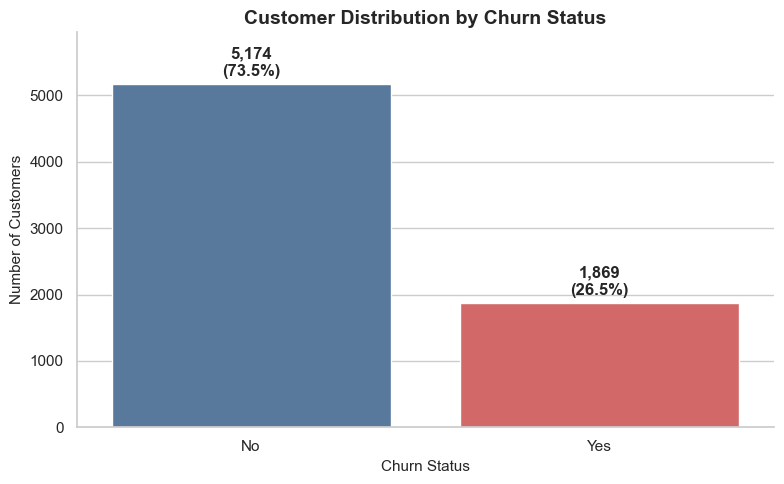

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=churn_summary,
    x="Churn",
    y="CustomerCount",
    hue="Churn",
    palette=churn_colors,
    legend=False,
    ax=ax
)

for bar, percentage in zip(
    ax.patches,
    churn_summary["Percentage"]
):
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 80,
        f"{int(height):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_title("Customer Distribution by Churn Status")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, churn_summary["CustomerCount"].max() * 1.15)

sns.despine()
plt.tight_layout()
#simpan grafik
figure_path = Path("../images/overall_churn_distribution.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Finding:**

Dari 7.043 pelanggan, sebanyak 1.869 pelanggan atau 26,54% tercatat mengalami churn. Sementara itu, 5.174 pelanggan atau 73,46% masih bertahan.

Hasil ini menunjukkan bahwa sekitar satu dari empat pelanggan dalam dataset berhenti berlangganan. Kelompok pelanggan churn cukup besar untuk menjadi perhatian bisnis dan perlu dianalisis lebih lanjut untuk mengetahui karakteristik yang paling berkaitan dengan churn.

### 5.3 Tenure Analysis

Analisis ini membandingkan masa berlangganan antara pelanggan yang churn dan tidak churn. Tujuannya adalah melihat apakah pelanggan yang berhenti cenderung memiliki masa berlangganan lebih pendek.

#### 5.3.1 Tenure Summary by Churn Status

In [44]:
tenure_summary = (
    df_clean
    .groupby("Churn")["tenure"]
    .agg(
        CustomerCount="count",
        MeanTenure="mean",
        MedianTenure="median",
        MinimumTenure="min",
        MaximumTenure="max"
    )
    .reindex(["No", "Yes"])
    .round(2)
)

tenure_summary

,CustomerCount,MeanTenure,MedianTenure,MinimumTenure,MaximumTenure
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


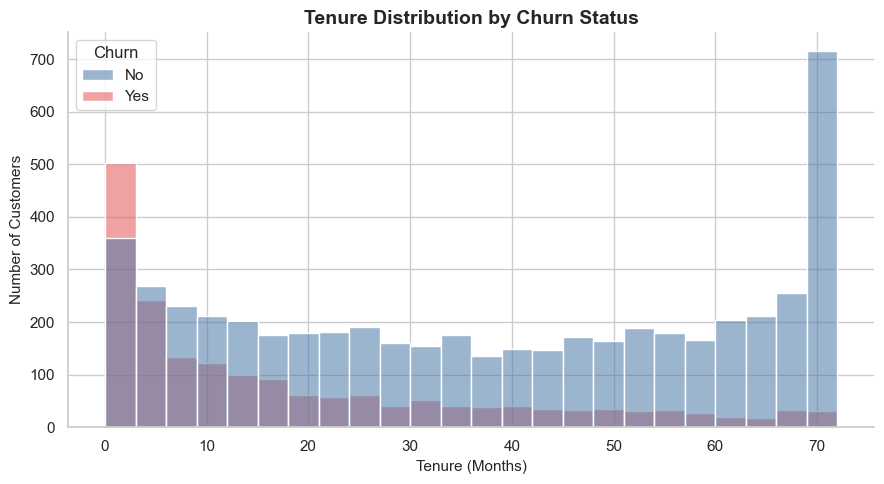

In [45]:
#Tenure Distribution
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    hue_order=["No", "Yes"],
    palette=churn_colors,
    bins=24,
    multiple="layer",
    alpha=0.55,
    ax=ax
)

ax.set_title("Tenure Distribution by Churn Status")
ax.set_xlabel("Tenure (Months)")
ax.set_ylabel("Number of Customers")

sns.despine()
plt.tight_layout()

fig.savefig(
    images_path / "tenure_distribution_by_churn.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

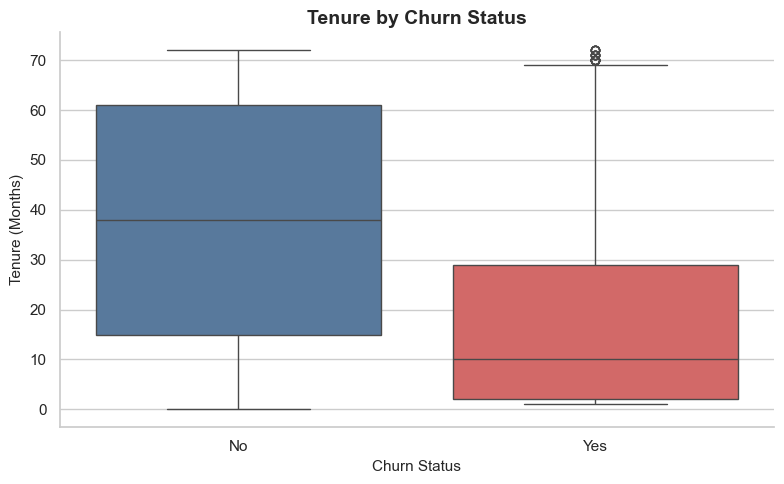

In [46]:
#Tenure Boxplot
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    hue="Churn",
    order=["No", "Yes"],
    palette=churn_colors,
    legend=False,
    ax=ax
)

ax.set_title("Tenure by Churn Status")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Tenure (Months)")

sns.despine()
plt.tight_layout()
plt.show()

**Finding:**

Pelanggan yang mengalami churn memiliki median tenure 10 bulan, sedangkan pelanggan yang tidak churn memiliki median tenure 38 bulan. Rata-rata tenure kelompok churn juga lebih rendah, yaitu 17,98 bulan dibandingkan 37,57 bulan pada kelompok tidak churn.

Distribusi menunjukkan bahwa pelanggan churn lebih banyak terkonsentrasi pada masa berlangganan yang pendek. Pelanggan dengan masa berlangganan panjang lebih banyak ditemukan pada kelompok yang bertahan.

Temuan awal ini menunjukkan adanya hubungan antara masa berlangganan dan churn. Namun, analisis deskriptif ini belum membuktikan bahwa tenure yang pendek menyebabkan churn.

#### 5.3.2 Churn Rate by Tenure Group

Pelanggan dikelompokkan berdasarkan masa berlangganan untuk membandingkan churn rate pada setiap tahap hubungan pelanggan.

In [47]:
tenure_group_summary = (
    df_clean
    .groupby("TenureGroup", observed=True)
    .agg(
        CustomerCount=("customerID", "count"),
        ChurnedCustomers=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean")
    )
    .reset_index()
)

tenure_group_summary["CustomerShare"] = (
    tenure_group_summary["CustomerCount"]
    / len(df_clean)
)

tenure_group_summary

,TenureGroup,CustomerCount,ChurnedCustomers,ChurnRate,CustomerShare
0,New Customer,2186,1037,0.474382,0.310379
1,Early Tenure,1024,294,0.287109,0.145393
2,Established Customer,1594,325,0.203890,0.226324
3,Long-Term Customer,2239,213,0.095132,0.317904


In [48]:
tenure_group_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}",
    "CustomerShare": "{:.2%}"
})

,TenureGroup,CustomerCount,ChurnedCustomers,ChurnRate,CustomerShare
0,New Customer,"2,186","1,037",47.44%,31.04%
1,Early Tenure,"1,024",294,28.71%,14.54%
2,Established Customer,"1,594",325,20.39%,22.63%
3,Long-Term Customer,"2,239",213,9.51%,31.79%


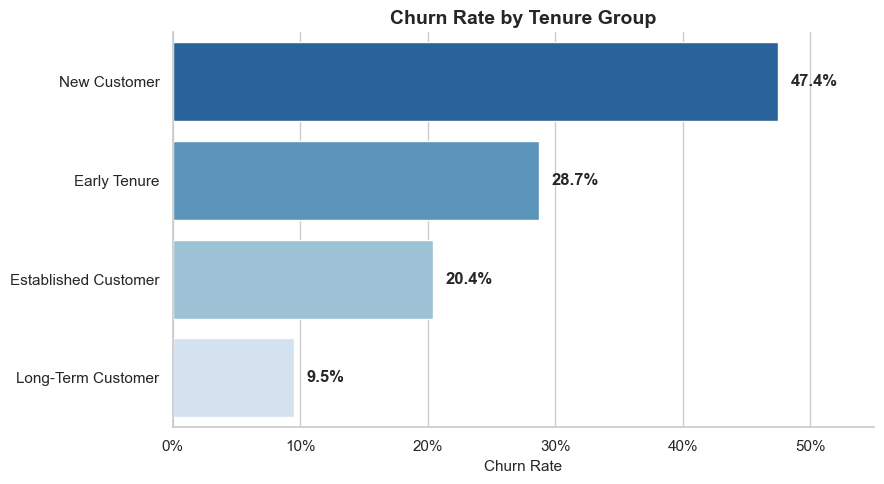

In [49]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=tenure_group_summary,
    x="ChurnRate",
    y="TenureGroup",
    hue="TenureGroup",
    palette="Blues_r",
    legend=False,
    ax=ax
)

for bar in ax.patches:
    churn_rate = bar.get_width()

    ax.text(
        churn_rate + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{churn_rate:.1%}",
        va="center",
        fontweight="bold"
    )

ax.set_title("Churn Rate by Tenure Group")
ax.set_xlabel("Churn Rate")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0%}")
)
ax.set_xlim(0, 0.55)

sns.despine()
plt.tight_layout()

fig.savefig(
    images_path / "tenure_group_churn_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [50]:
# Reusable function to create churn summary for any categorical column
def create_churn_summary(data, column):
    summary = (
        data
        .groupby(column)
        .agg(
            CustomerCount=("customerID", "count"),
            ChurnedCustomers=("ChurnFlag", "sum"),
            ChurnRate=("ChurnFlag", "mean")
        )
        .reset_index()
    )

    return summary

#### 5.3.3 New Customer Profile

Analisis sebelumnya menunjukkan bahwa kelompok `New Customer`, yaitu pelanggan dengan tenure 0–12 bulan, memiliki churn rate tertinggi sebesar 47,44%.

Bagian ini membandingkan karakteristik pelanggan di dalam kelompok `New Customer` untuk mengetahui kelompok mana yang memiliki churn rate lebih tinggi.

Analisis ini membantu mempersempit kelompok prioritas pada 12 bulan pertama. Hasilnya menunjukkan hubungan antarvariabel dan belum menjelaskan alasan langsung pelanggan berhenti.

In [51]:
new_customers = df_clean[
    df_clean["TenureGroup"] == "New Customer"
].copy()

new_internet_customers = new_customers[
    new_customers["InternetService"] != "No"
].copy()

print(
    f"New customers: "
    f"{len(new_customers):,}"
)

print(
    f"New customer churn rate: "
    f"{new_customers['ChurnFlag'].mean():.2%}"
)

New customers: 2,186
New customer churn rate: 47.44%


In [52]:
def summarize_customer_group(
    data,
    variable,
    category,
    condition
):
    group = data.loc[condition]

    return {
        "Variable": variable,
        "Category": category,
        "CustomerCount": len(group),
        "ChurnedCustomers": group["ChurnFlag"].sum(),
        "ChurnRate": group["ChurnFlag"].mean()
    }

In [53]:
new_customer_comparison = pd.DataFrame([
    summarize_customer_group(
        new_customers,
        "Contract",
        "Month-to-month",
        new_customers["Contract"]
        == "Month-to-month"
    ),
    summarize_customer_group(
        new_customers,
        "Contract",
        "Fixed-term",
        new_customers["Contract"]
        != "Month-to-month"
    ),
    summarize_customer_group(
        new_customers,
        "Internet Service",
        "Fiber optic",
        new_customers["InternetService"]
        == "Fiber optic"
    ),
    summarize_customer_group(
        new_customers,
        "Internet Service",
        "DSL",
        new_customers["InternetService"]
        == "DSL"
    ),
    summarize_customer_group(
        new_customers,
        "Internet Service",
        "No internet",
        new_customers["InternetService"]
        == "No"
    ),
    summarize_customer_group(
        new_customers,
        "Payment Method",
        "Electronic check",
        new_customers["PaymentMethod"]
        == "Electronic check"
    ),
    summarize_customer_group(
        new_customers,
        "Payment Method",
        "Other payment methods",
        new_customers["PaymentMethod"]
        != "Electronic check"
    ),
    summarize_customer_group(
        new_customers,
        "Paperless Billing",
        "Yes",
        new_customers["PaperlessBilling"]
        == "Yes"
    ),
    summarize_customer_group(
        new_customers,
        "Paperless Billing",
        "No",
        new_customers["PaperlessBilling"]
        == "No"
    ),
    summarize_customer_group(
        new_internet_customers,
        "Online Security",
        "No",
        new_internet_customers["OnlineSecurity"]
        == "No"
    ),
    summarize_customer_group(
        new_internet_customers,
        "Online Security",
        "Yes",
        new_internet_customers["OnlineSecurity"]
        == "Yes"
    ),
    summarize_customer_group(
        new_internet_customers,
        "Tech Support",
        "No",
        new_internet_customers["TechSupport"]
        == "No"
    ),
    summarize_customer_group(
        new_internet_customers,
        "Tech Support",
        "Yes",
        new_internet_customers["TechSupport"]
        == "Yes"
    )
])

In [54]:
new_customer_comparison.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,Variable,Category,CustomerCount,ChurnedCustomers,ChurnRate
0,Contract,Month-to-month,"1,994","1,024",51.35%
1,Contract,Fixed-term,192,13,6.77%
2,Internet Service,Fiber optic,923,645,69.88%
3,Internet Service,DSL,750,300,40.00%
4,Internet Service,No internet,513,92,17.93%
5,Payment Method,Electronic check,978,606,61.96%
6,Payment Method,Other payment methods,"1,208",431,35.68%
7,Paperless Billing,Yes,"1,286",739,57.47%
8,Paperless Billing,No,900,298,33.11%
9,Online Security,No,"1,402",853,60.84%


**Finding:**

Kelompok `New Customer`, yaitu pelanggan dengan tenure 0–12 bulan, memiliki churn rate keseluruhan sebesar 47,44%. Namun, churn tidak tersebar secara merata di dalam kelompok tersebut.

Perbedaan yang terlihat meliputi:

- Fiber optic memiliki churn rate 69,88%, dibandingkan 40,00% pada DSL dan 17,93% pada pelanggan tanpa internet.
- Electronic check memiliki churn rate 61,96%, dibandingkan 35,68% pada metode pembayaran lainnya.
- Pelanggan tanpa Online Security memiliki churn rate 60,84%, dibandingkan 33,95% pada pelanggan yang menggunakannya.
- Pelanggan tanpa Tech Support memiliki churn rate 60,29%, dibandingkan 37,81% pada pelanggan yang menggunakannya.
- Month-to-month memiliki churn rate 51,35%, dibandingkan 6,77% pada kontrak fixed-term.

Hasil ini menunjukkan bahwa churn pada kelompok New Customer lebih terkonsentrasi pada pelanggan fiber optic, pengguna electronic check, pelanggan month-to-month, serta pelanggan tanpa layanan dukungan.

Kategori tersebut dapat saling tumpang tindih sehingga jumlah pelanggan pada setiap kategori tidak boleh dijumlahkan. Analisis ini juga belum membuktikan bahwa karakteristik tersebut menyebabkan churn.

### 5.4 Customer Demographics Analysis

Analisis ini membandingkan churn rate berdasarkan karakteristik demografi pelanggan, yaitu gender, status senior citizen, partner, dan dependents.

#### 5.4.1 Churn by Gender

In [55]:
gender_summary = create_churn_summary(
    df_clean,
    "gender"
)

gender_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,gender,CustomerCount,ChurnedCustomers,ChurnRate
0,Female,"3,488",939,26.92%
1,Male,"3,555",930,26.16%


#### 5.4.2 Churn by Senior Citizen Status

In [56]:
senior_summary = create_churn_summary(
    df_clean,
    "SeniorCitizen"
)

senior_summary["SeniorCitizen"] = (
    senior_summary["SeniorCitizen"]
    .map({
        0: "No",
        1: "Yes"
    })
)

senior_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,SeniorCitizen,CustomerCount,ChurnedCustomers,ChurnRate
0,No,"5,901","1,393",23.61%
1,Yes,"1,142",476,41.68%


#### 5.4.3 Churn by Partner Status

In [57]:
partner_summary = create_churn_summary(
    df_clean,
    "Partner"
)

partner_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,Partner,CustomerCount,ChurnedCustomers,ChurnRate
0,No,"3,641","1,200",32.96%
1,Yes,"3,402",669,19.66%


#### 5.4.4 Churn by Dependents Status

In [58]:
dependents_summary = create_churn_summary(
    df_clean,
    "Dependents"
)

dependents_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,Dependents,CustomerCount,ChurnedCustomers,ChurnRate
0,No,"4,933","1,543",31.28%
1,Yes,"2,110",326,15.45%


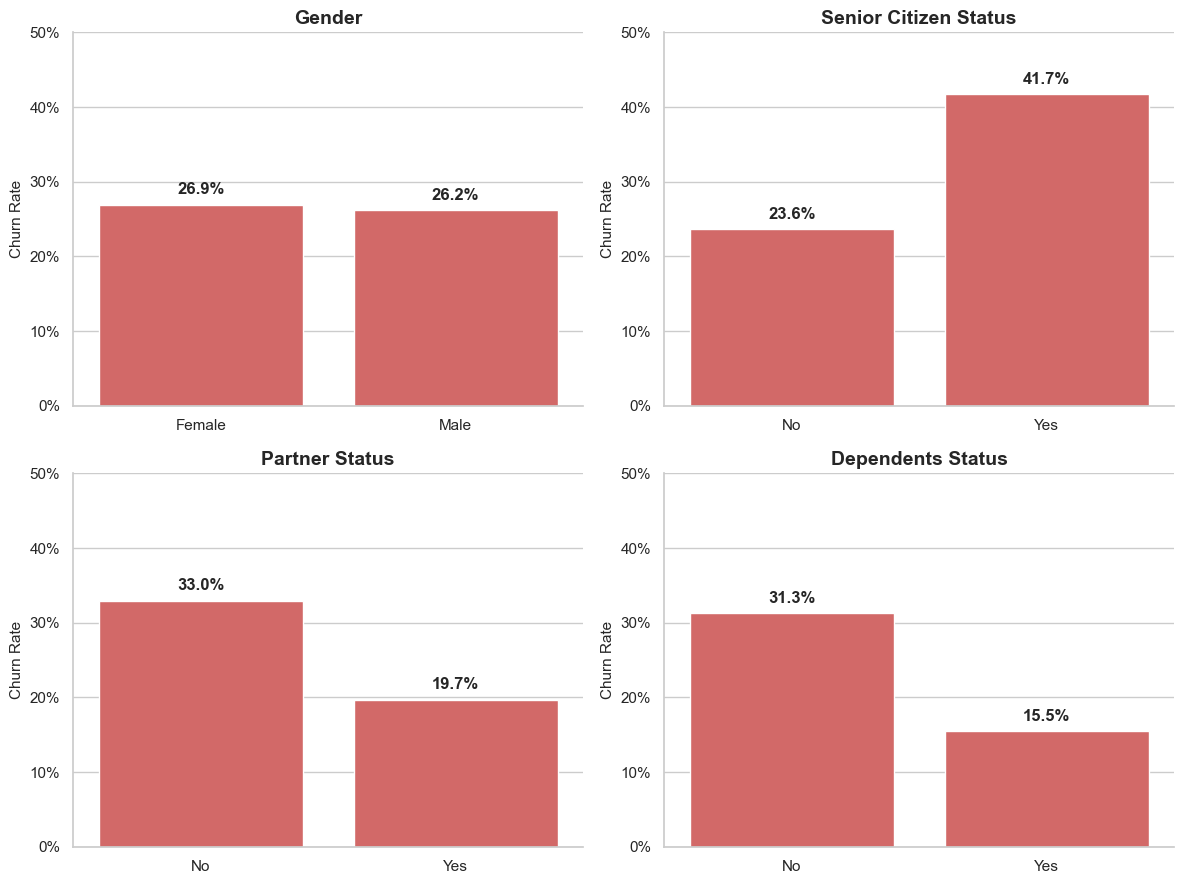

In [59]:
demographic_summaries = [
    (gender_summary, "gender", "Gender"),
    (
        senior_summary,
        "SeniorCitizen",
        "Senior Citizen Status"
    ),
    (partner_summary, "Partner", "Partner Status"),
    (
        dependents_summary,
        "Dependents",
        "Dependents Status"
    )
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

axes = axes.flatten()

for ax, (summary, column, title) in zip(
    axes,
    demographic_summaries
):
    sns.barplot(
        data=summary,
        x=column,
        y="ChurnRate",
        color="#E45756",
        ax=ax
    )

    for bar in ax.patches:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.1%}",
            ha="center",
            va="bottom",
            fontweight="bold"
        )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Churn Rate")
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda value, _: f"{value:.0%}"
        )
    )
    ax.set_ylim(0, 0.50)

sns.despine()
plt.tight_layout()
plt.show()

**Findings:**

- Churn rate pelanggan perempuan adalah 26,92%, sedangkan pelanggan laki-laki 26,16%. Selisih yang kecil menunjukkan bahwa gender tidak memperlihatkan perbedaan churn yang berarti secara deskriptif.
- Senior citizen memiliki churn rate 41,68%, lebih tinggi dibandingkan pelanggan non-senior sebesar 23,61%.
- Pelanggan tanpa partner memiliki churn rate 32,96%, dibandingkan 19,66% pada pelanggan yang memiliki partner.
- Pelanggan tanpa dependents memiliki churn rate 31,28%, dibandingkan 15,45% pada pelanggan yang memiliki dependents.

Secara deskriptif, status senior citizen, partner, dan dependents menunjukkan perbedaan churn rate yang lebih besar dibandingkan gender. Namun, kelompok-kelompok tersebut dapat saling berkaitan dan juga dipengaruhi oleh karakteristik lain seperti tenure, kontrak, atau layanan. Oleh karena itu, hasil ini belum menunjukkan hubungan sebab-akibat.

### 5.5 Contract and Billing Analysis

Analisis ini membandingkan churn rate berdasarkan jenis kontrak, penggunaan paperless billing, dan metode pembayaran pelanggan.

#### 5.5.1 Churn by Contract Type

In [60]:
contract_summary = create_churn_summary(
    df_clean,
    "Contract"
)

contract_order = [
    "Month-to-month",
    "One year",
    "Two year"
]

contract_summary["Contract"] = pd.Categorical(
    contract_summary["Contract"],
    categories=contract_order,
    ordered=True
)

contract_summary = (
    contract_summary
    .sort_values("Contract")
    .reset_index(drop=True)
)

contract_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,Contract,CustomerCount,ChurnedCustomers,ChurnRate
0,Month-to-month,"3,875","1,655",42.71%
1,One year,"1,473",166,11.27%
2,Two year,"1,695",48,2.83%


#### 5.5.2 Churn by Paperless Billing

In [61]:
paperless_summary = create_churn_summary(
    df_clean,
    "PaperlessBilling"
)

paperless_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,PaperlessBilling,CustomerCount,ChurnedCustomers,ChurnRate
0,No,"2,872",469,16.33%
1,Yes,"4,171","1,400",33.57%


#### 5.5.3 Churn by Payment Method

In [62]:
payment_summary = create_churn_summary(
    df_clean,
    "PaymentMethod"
)

payment_summary = (
    payment_summary
    .sort_values(
        "ChurnRate",
        ascending=False
    )
    .reset_index(drop=True)
)

payment_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,PaymentMethod,CustomerCount,ChurnedCustomers,ChurnRate
0,Electronic check,"2,365","1,071",45.29%
1,Mailed check,"1,612",308,19.11%
2,Bank transfer (automatic),"1,544",258,16.71%
3,Credit card (automatic),"1,522",232,15.24%


#### Contract and Billing Visualization

In [63]:
contract_plot = (
    contract_summary
    .sort_values(
        "ChurnRate",
        ascending=True
    )
)

paperless_plot = (
    paperless_summary
    .sort_values(
        "ChurnRate",
        ascending=True
    )
)

payment_plot = (
    payment_summary
    .sort_values(
        "ChurnRate",
        ascending=True
    )
)

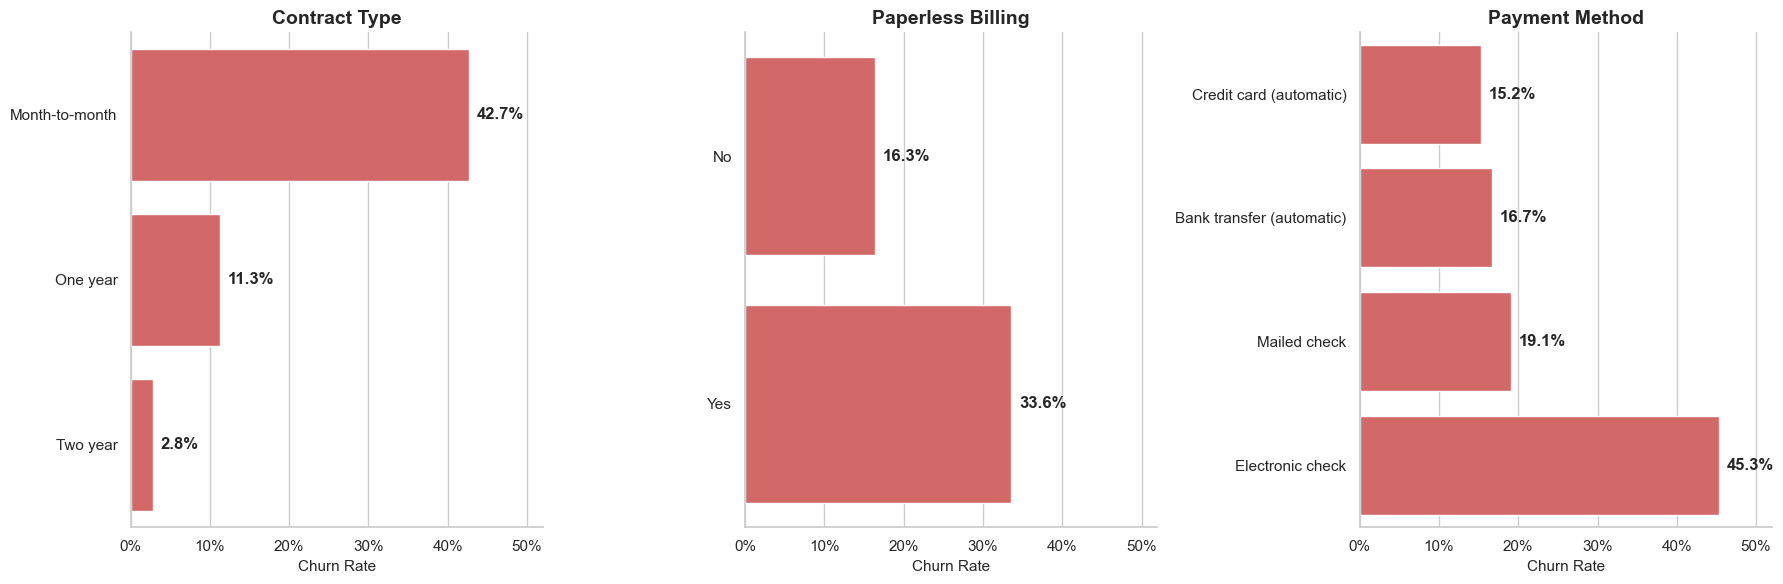

In [64]:
plot_configs = [
    (
        contract_plot,
        "Contract",
        "Contract Type"
    ),
    (
        paperless_plot,
        "PaperlessBilling",
        "Paperless Billing"
    ),
    (
        payment_plot,
        "PaymentMethod",
        "Payment Method"
    )
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

for ax, (summary, column, title) in zip(
    axes,
    plot_configs
):
    sns.barplot(
        data=summary,
        x="ChurnRate",
        y=column,
        color="#E45756",
        ax=ax
    )

    for bar in ax.patches:
        width = bar.get_width()

        ax.text(
            width + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1%}",
            ha="left",
            va="center",
            fontweight="bold"
        )

    ax.set_title(title)
    ax.set_xlabel("Churn Rate")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda value, _: f"{value:.0%}"
        )
    )
    ax.set_xlim(0, 0.52)

sns.despine()
plt.tight_layout()

fig.savefig(
    images_path / "contract_billing_churn_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [65]:
month_to_month_churn = contract_summary.loc[
    contract_summary["Contract"] == "Month-to-month",
    "ChurnedCustomers"
].iloc[0]

month_to_month_churn_share = (
    month_to_month_churn
    / df_clean["ChurnFlag"].sum()
)

print(
    "Share of churned customers with "
    f"month-to-month contracts: "
    f"{month_to_month_churn_share:.2%}"
)

Share of churned customers with month-to-month contracts: 88.55%


**Findings:**

- Pelanggan dengan kontrak `Month-to-month` memiliki churn rate tertinggi sebesar 42,71%. Churn rate menurun menjadi 11,27% pada kontrak satu tahun dan 2,83% pada kontrak dua tahun.
- Sebanyak 1.655 dari 1.869 pelanggan churn menggunakan kontrak bulanan. Artinya, sekitar 88,55% pelanggan churn berasal dari kelompok ini.
- Pelanggan yang menggunakan paperless billing memiliki churn rate 33,57%, dibandingkan 16,33% pada pelanggan yang tidak menggunakannya.
- `Electronic check` memiliki churn rate tertinggi di antara metode pembayaran, yaitu 45,29%. Metode pembayaran otomatis memiliki churn rate yang lebih rendah, yaitu 16,71% untuk bank transfer dan 15,24% untuk credit card.

Jenis kontrak menunjukkan perbedaan churn rate yang paling besar pada bagian ini. Meskipun demikian, kontrak, paperless billing, dan metode pembayaran dapat digunakan oleh kelompok pelanggan yang sama. Analisis deskriptif ini belum dapat memisahkan pengaruh masing-masing variabel atau membuktikan bahwa salah satunya menyebabkan churn.

### 5.6 Charges Analysis

Analisis ini membandingkan biaya bulanan dan total biaya antara pelanggan yang churn dan tidak churn. `MonthlyCharges` menunjukkan beban biaya saat ini, sedangkan `TotalCharges` merupakan akumulasi biaya selama masa berlangganan.

#### 5.6.1 Charges Summary by Churn Status

In [66]:
charges_summary = (
    df_clean
    .groupby("Churn")
    .agg(
        CustomerCount=("customerID", "count"),
        MeanMonthlyCharges=("MonthlyCharges", "mean"),
        MedianMonthlyCharges=("MonthlyCharges", "median"),
        MeanTotalCharges=("TotalCharges", "mean"),
        MedianTotalCharges=("TotalCharges", "median")
    )
    .reindex(["No", "Yes"])
    .round(2)
)

charges_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "MeanMonthlyCharges": "${:,.2f}",
    "MedianMonthlyCharges": "${:,.2f}",
    "MeanTotalCharges": "${:,.2f}",
    "MedianTotalCharges": "${:,.2f}"
})

,CustomerCount,MeanMonthlyCharges,MedianMonthlyCharges,MeanTotalCharges,MedianTotalCharges
Churn,,,,,
No,"5,174",$61.27,$64.43,"$2,549.91","$1,679.52"
Yes,"1,869",$74.44,$79.65,"$1,531.80",$703.55


In [67]:
mean_monthly_no = charges_summary.loc[
    "No",
    "MeanMonthlyCharges"
]

mean_monthly_yes = charges_summary.loc[
    "Yes",
    "MeanMonthlyCharges"
]

monthly_charge_difference = (
    mean_monthly_yes - mean_monthly_no
)

monthly_charge_percentage_difference = (
    monthly_charge_difference
    / mean_monthly_no
)

print(
    "Mean monthly charge difference: "
    f"${monthly_charge_difference:,.2f}"
)

print(
    "Percentage difference: "
    f"{monthly_charge_percentage_difference:.2%}"
)

Mean monthly charge difference: $13.17
Percentage difference: 21.50%


rata-rata biaya bulanan kelompok churn sekitar 21,5% lebih tinggi daripada kelompok yang bertahan.

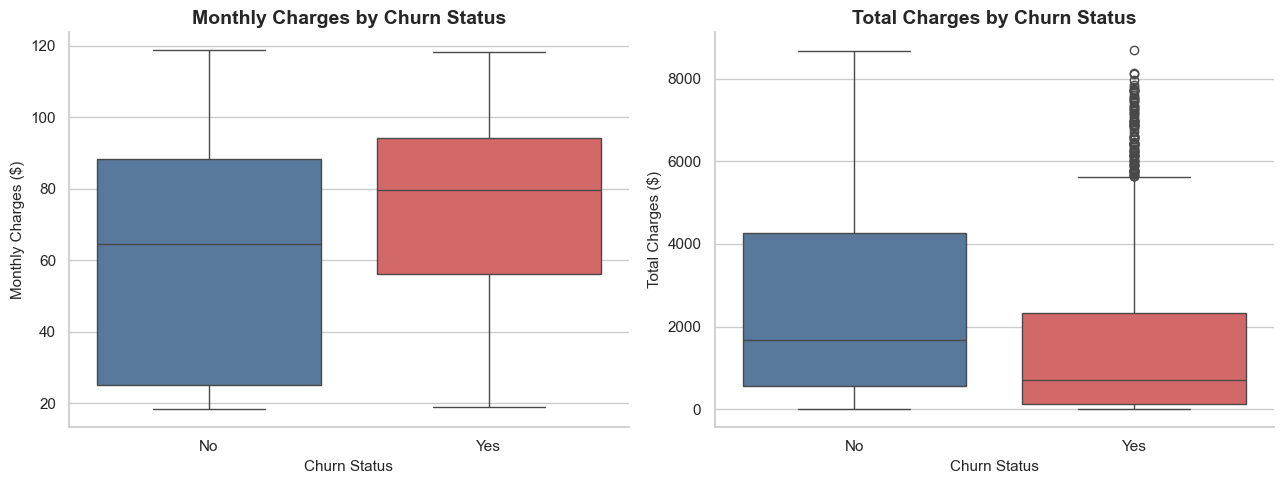

In [68]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    order=["No", "Yes"],
    palette=churn_colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Monthly Charges by Churn Status")
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Monthly Charges ($)")

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="TotalCharges",
    hue="Churn",
    order=["No", "Yes"],
    palette=churn_colors,
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Total Charges by Churn Status")
axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Total Charges ($)")

sns.despine()
plt.tight_layout()
plt.show()

In [69]:
charges_correlation = (
    df_clean[
        [
            "tenure",
            "MonthlyCharges",
            "TotalCharges"
        ]
    ]
    .corr()
    .round(3)
)

charges_correlation

,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


**Findings:**

- Pelanggan churn memiliki rata-rata `MonthlyCharges` sebesar $74,44, lebih tinggi $13,17 atau sekitar 21,50% dibandingkan pelanggan yang bertahan dengan rata-rata $61,27.
- Median biaya bulanan pelanggan churn juga lebih tinggi, yaitu $79,65 dibandingkan $64,43 pada pelanggan yang bertahan.
- Pelanggan churn memiliki rata-rata dan median `TotalCharges` yang lebih rendah.
- Korelasi antara `tenure` dan `TotalCharges` adalah sekitar 0,826, yang menunjukkan hubungan positif yang kuat.

Nilai `TotalCharges` yang lebih rendah pada pelanggan churn perlu ditafsirkan bersama dengan tenure. Pelanggan churn memiliki masa berlangganan yang lebih pendek, sehingga mereka memiliki lebih sedikit waktu untuk mengakumulasi total biaya.

Hasil deskriptif menunjukkan bahwa biaya bulanan yang lebih tinggi berkaitan dengan churn. Namun, perbedaan biaya dapat berhubungan dengan jenis layanan yang digunakan, sehingga analisis layanan diperlukan sebelum membuat kesimpulan bisnis.

### 5.7 Internet and Service Analysis

Analisis ini membandingkan churn berdasarkan jenis layanan internet dan penggunaan layanan tambahan. Pelanggan tanpa layanan internet dipisahkan dari pelanggan internet yang tidak menggunakan add-on karena kedua kondisi tersebut memiliki arti berbeda.

#### 5.7.1 Churn by Internet Service

In [70]:
internet_summary = create_churn_summary(
    df_clean,
    "InternetService"
)

internet_summary = (
    internet_summary
    .sort_values(
        "ChurnRate",
        ascending=False
    )
    .reset_index(drop=True)
)

internet_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,InternetService,CustomerCount,ChurnedCustomers,ChurnRate
0,Fiber optic,"3,096","1,297",41.89%
1,DSL,"2,421",459,18.96%
2,No,"1,526",113,7.40%


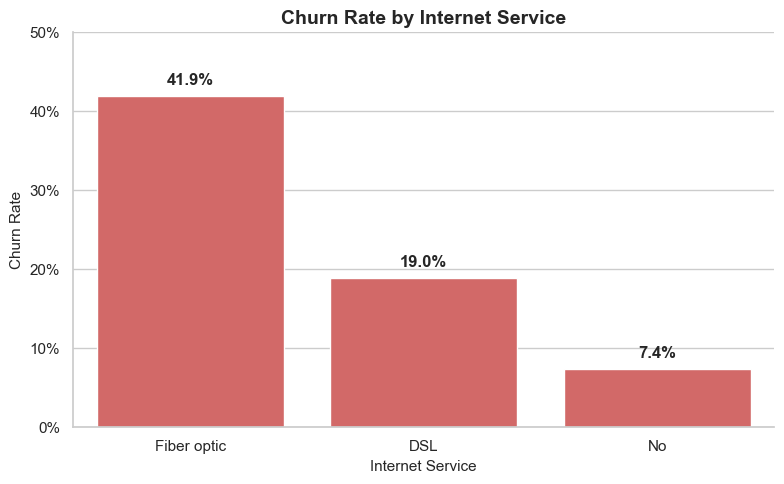

In [71]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=internet_summary,
    x="InternetService",
    y="ChurnRate",
    color="#E45756",
    ax=ax
)

for bar in ax.patches:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.1%}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_title("Churn Rate by Internet Service")
ax.set_xlabel("Internet Service")
ax.set_ylabel("Churn Rate")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _: f"{value:.0%}"
    )
)
ax.set_ylim(0, 0.50)

sns.despine()
plt.tight_layout()
plt.show()

#### 5.7.2 Churn by Internet Add-On

In [72]:
internet_customers = df_clean[
    df_clean["InternetService"] != "No"
].copy()

print(
    f"Internet customers: "
    f"{len(internet_customers):,}"
)

Internet customers: 5,517


In [73]:
addon_labels = {
    "OnlineSecurity": "Online Security",
    "OnlineBackup": "Online Backup",
    "DeviceProtection": "Device Protection",
    "TechSupport": "Tech Support",
    "StreamingTV": "Streaming TV",
    "StreamingMovies": "Streaming Movies"
}

addon_summary_list = []

for column, label in addon_labels.items():
    summary = create_churn_summary(
        internet_customers,
        column
    )

    summary = summary.rename(
        columns={column: "SubscriptionStatus"}
    )

    summary["Service"] = label

    addon_summary_list.append(summary)

addon_summary = pd.concat(
    addon_summary_list,
    ignore_index=True
)

addon_summary = addon_summary[
    [
        "Service",
        "SubscriptionStatus",
        "CustomerCount",
        "ChurnedCustomers",
        "ChurnRate"
    ]
]

addon_summary.head()

,Service,SubscriptionStatus,CustomerCount,ChurnedCustomers,ChurnRate
0,Online Security,No,3498,1461,0.417667
1,Online Security,Yes,2019,295,0.146112
2,Online Backup,No,3088,1233,0.399288
3,Online Backup,Yes,2429,523,0.215315
4,Device Protection,No,3095,1211,0.391276


In [74]:
addon_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,Service,SubscriptionStatus,CustomerCount,ChurnedCustomers,ChurnRate
0,Online Security,No,"3,498","1,461",41.77%
1,Online Security,Yes,"2,019",295,14.61%
2,Online Backup,No,"3,088","1,233",39.93%
3,Online Backup,Yes,"2,429",523,21.53%
4,Device Protection,No,"3,095","1,211",39.13%
5,Device Protection,Yes,"2,422",545,22.50%
6,Tech Support,No,"3,473","1,446",41.64%
7,Tech Support,Yes,"2,044",310,15.17%
8,Streaming TV,No,"2,810",942,33.52%
9,Streaming TV,Yes,"2,707",814,30.07%


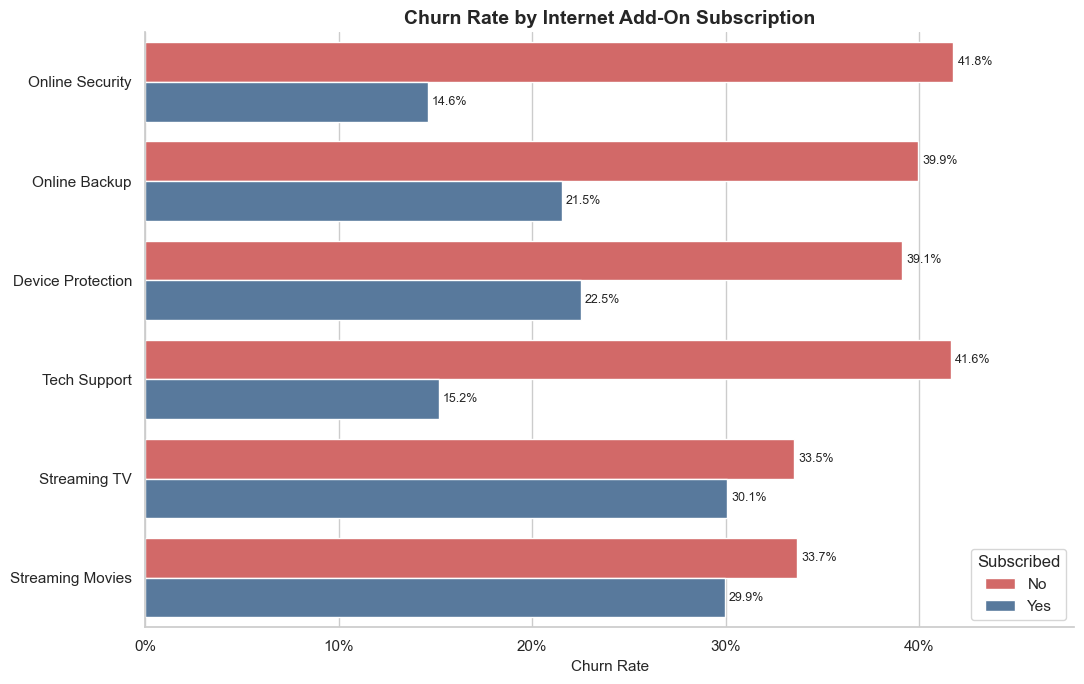

In [75]:
fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=addon_summary,
    x="ChurnRate",
    y="Service",
    hue="SubscriptionStatus",
    hue_order=["No", "Yes"],
    palette={
        "No": "#E45756",
        "Yes": "#4C78A8"
    },
    ax=ax
)

for container in ax.containers:
    labels = [
        f"{value:.1%}"
        for value in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=9
    )

ax.set_title("Churn Rate by Internet Add-On Subscription")
ax.set_xlabel("Churn Rate")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _: f"{value:.0%}"
    )
)
ax.set_xlim(0, 0.48)
ax.legend(
    title="Subscribed",
    loc="lower right"
)

sns.despine()
plt.tight_layout()
plt.show()

**Findings:**

- Pelanggan fiber optic memiliki churn rate tertinggi sebesar 41,89%, dibandingkan 18,96% pada pelanggan DSL dan 7,40% pada pelanggan tanpa layanan internet.
- Pelanggan internet tanpa `OnlineSecurity` memiliki churn rate 41,77%, sedangkan pelanggan yang menggunakan layanan tersebut memiliki churn rate 14,61%.
- Pelanggan tanpa `TechSupport` memiliki churn rate 41,64%, dibandingkan 15,17% pada pelanggan yang menggunakannya.
- Penggunaan `OnlineBackup` dan `DeviceProtection` juga berkaitan dengan churn rate yang lebih rendah.
- Perbedaan churn rate pada layanan streaming lebih kecil. Pelanggan dengan dan tanpa `StreamingTV` atau `StreamingMovies` memiliki churn rate yang relatif berdekatan.

Secara deskriptif, `OnlineSecurity` dan `TechSupport` menunjukkan perbedaan churn rate paling besar di antara layanan tambahan. Namun, pelanggan yang menggunakan layanan tersebut mungkin juga memiliki tenure lebih panjang atau jenis kontrak yang berbeda. Oleh karena itu, hasil ini belum membuktikan bahwa pembelian add-on secara langsung mengurangi churn.

#### 5.7.3 Churn by Number of Internet Add-Ons

Analisis ini memeriksa perubahan churn rate berdasarkan jumlah layanan tambahan yang digunakan. Hanya pelanggan dengan layanan internet yang disertakan agar nilai nol berarti pelanggan tidak menggunakan add-on.

In [76]:
addon_count_summary = (
    internet_customers
    .groupby("InternetAddOnCount")
    .agg(
        CustomerCount=("customerID", "count"),
        ChurnedCustomers=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean"),
        MeanTenure=("tenure", "mean"),
        MeanMonthlyCharges=("MonthlyCharges", "mean")
    )
    .reset_index()
)

addon_count_summary

,InternetAddOnCount,CustomerCount,ChurnedCustomers,ChurnRate,MeanTenure,MeanMonthlyCharges
0,0,693,362,0.522367,10.002886,58.586724
1,1,966,442,0.457557,16.868530,65.574275
2,2,1033,370,0.358180,26.042594,72.417473
3,3,1118,306,0.273703,36.671735,80.110510
4,4,852,190,0.223005,47.215962,87.771538
5,5,571,71,0.124343,55.264448,92.176007
6,6,284,15,0.052817,65.010563,99.365317


In [77]:
addon_count_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}",
    "MeanTenure": "{:.2f}",
    "MeanMonthlyCharges": "${:,.2f}"
})

,InternetAddOnCount,CustomerCount,ChurnedCustomers,ChurnRate,MeanTenure,MeanMonthlyCharges
0,0,693,362,52.24%,10.00,$58.59
1,1,966,442,45.76%,16.87,$65.57
2,2,"1,033",370,35.82%,26.04,$72.42
3,3,"1,118",306,27.37%,36.67,$80.11
4,4,852,190,22.30%,47.22,$87.77
5,5,571,71,12.43%,55.26,$92.18
6,6,284,15,5.28%,65.01,$99.37


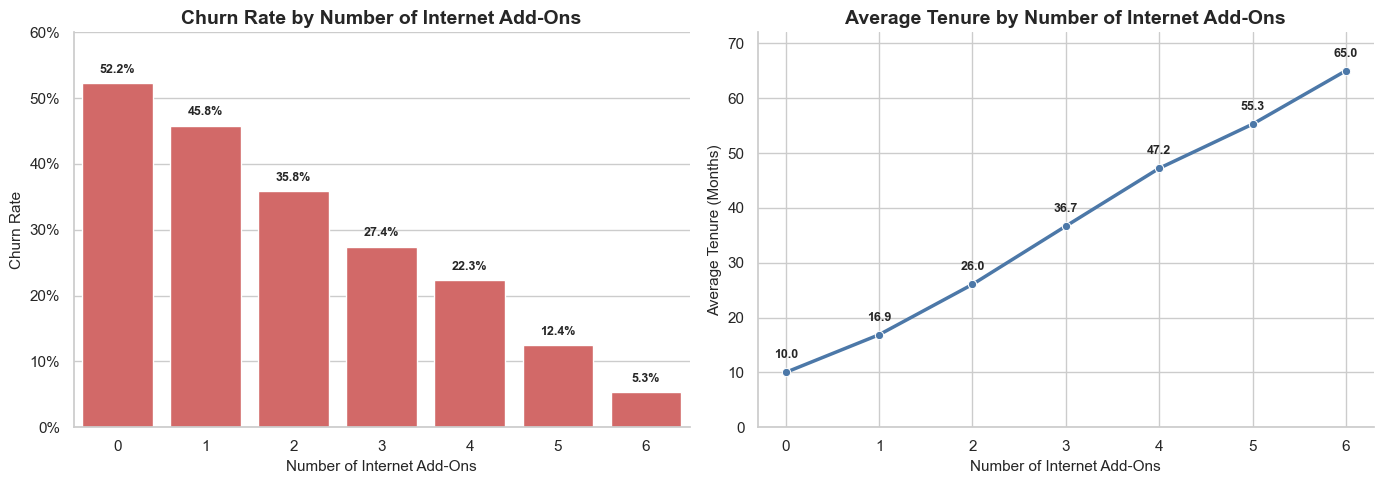

In [78]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.barplot(
    data=addon_count_summary,
    x="InternetAddOnCount",
    y="ChurnRate",
    color="#E45756",
    ax=axes[0]
)

for bar in axes[0].patches:
    height = bar.get_height()

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.012,
        f"{height:.1%}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

axes[0].set_title("Churn Rate by Number of Internet Add-Ons")
axes[0].set_xlabel("Number of Internet Add-Ons")
axes[0].set_ylabel("Churn Rate")
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _: f"{value:.0%}"
    )
)
axes[0].set_ylim(0, 0.60)

sns.lineplot(
    data=addon_count_summary,
    x="InternetAddOnCount",
    y="MeanTenure",
    marker="o",
    linewidth=2.5,
    color="#4C78A8",
    ax=axes[1]
)

for _, row in addon_count_summary.iterrows():
    axes[1].text(
        row["InternetAddOnCount"],
        row["MeanTenure"] + 2,
        f'{row["MeanTenure"]:.1f}',
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_title("Average Tenure by Number of Internet Add-Ons")
axes[1].set_xlabel("Number of Internet Add-Ons")
axes[1].set_ylabel("Average Tenure (Months)")
axes[1].set_ylim(0, 72)

sns.despine()
plt.tight_layout()
plt.show()

**Findings:**

Churn rate menunjukkan pola menurun seiring bertambahnya jumlah layanan tambahan:

- Pelanggan tanpa add-on memiliki churn rate 52,24%.
- Pelanggan dengan tiga add-on memiliki churn rate 27,37%.
- Pelanggan dengan seluruh enam add-on memiliki churn rate 5,28%.

Namun, rata-rata tenure juga meningkat bersama jumlah add-on. Pelanggan tanpa add-on memiliki rata-rata tenure 10 bulan, sedangkan pelanggan dengan enam add-on memiliki rata-rata tenure sekitar 65 bulan.

Pola ini menunjukkan bahwa jumlah add-on berkaitan dengan churn yang lebih rendah, tetapi juga berkaitan kuat dengan masa berlangganan yang lebih panjang. Pelanggan yang telah bertahan lama mungkin memiliki lebih banyak kesempatan atau kecenderungan untuk menambahkan layanan.

Oleh karena itu, analisis ini belum membuktikan bahwa menambahkan layanan secara langsung akan mengurangi churn. Hubungan antara add-on, tenure, dan churn perlu dipertimbangkan secara bersamaan saat menyusun rekomendasi.

### 5.8 Phone Service Analysis

Analisis ini membandingkan churn rate berdasarkan penggunaan layanan telepon dan multiple lines.

In [79]:
phone_summary = create_churn_summary(
    df_clean,
    "PhoneService"
)

multiple_lines_summary = create_churn_summary(
    df_clean,
    "MultipleLines"
)

In [80]:
phone_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,PhoneService,CustomerCount,ChurnedCustomers,ChurnRate
0,No,682,170,24.93%
1,Yes,"6,361","1,699",26.71%


In [81]:
multiple_lines_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}"
})

,MultipleLines,CustomerCount,ChurnedCustomers,ChurnRate
0,No,"3,390",849,25.04%
1,No phone service,682,170,24.93%
2,Yes,"2,971",850,28.61%


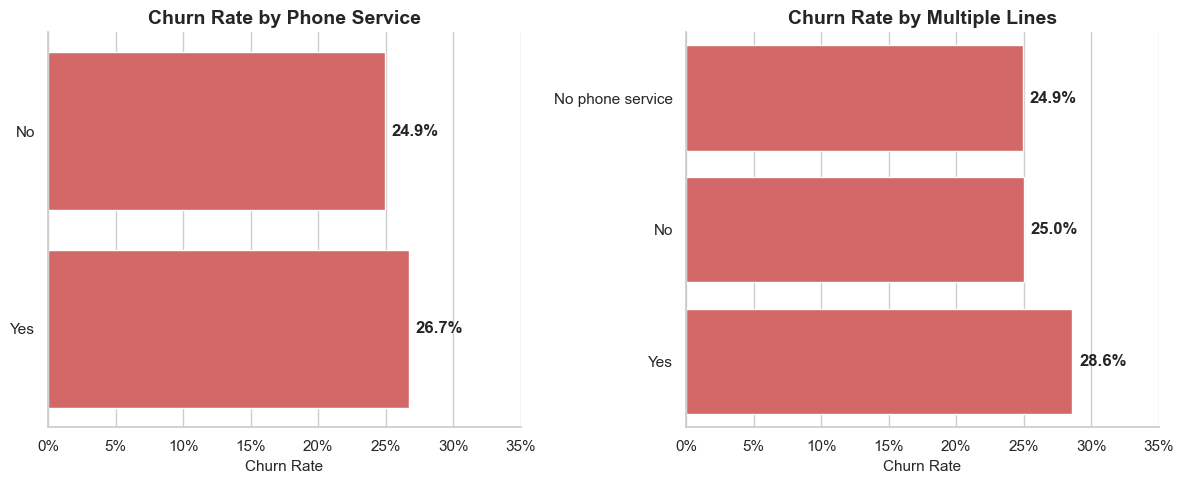

In [82]:
phone_plot = (
    phone_summary
    .sort_values("ChurnRate")
)

multiple_lines_plot = (
    multiple_lines_summary
    .sort_values("ChurnRate")
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

sns.barplot(
    data=phone_plot,
    x="ChurnRate",
    y="PhoneService",
    color="#E45756",
    ax=axes[0]
)

sns.barplot(
    data=multiple_lines_plot,
    x="ChurnRate",
    y="MultipleLines",
    color="#E45756",
    ax=axes[1]
)

for ax, title in zip(
    axes,
    [
        "Churn Rate by Phone Service",
        "Churn Rate by Multiple Lines"
    ]
):
    for bar in ax.patches:
        width = bar.get_width()

        ax.text(
            width + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1%}",
            ha="left",
            va="center",
            fontweight="bold"
        )

    ax.set_title(title)
    ax.set_xlabel("Churn Rate")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda value, _: f"{value:.0%}"
        )
    )
    ax.set_xlim(0, 0.35)

sns.despine()
plt.tight_layout()
plt.show()

**Findings:**

Pelanggan yang menggunakan phone service memiliki churn rate 26,71%, sedangkan pelanggan tanpa phone service memiliki churn rate 24,93%. Selisih antara kedua kelompok relatif kecil.

Pelanggan dengan multiple lines memiliki churn rate 28,61%, sedikit lebih tinggi daripada pelanggan tanpa multiple lines sebesar 25,04%. Pelanggan tanpa phone service memiliki churn rate 24,93%.

Secara deskriptif, `PhoneService` dan `MultipleLines` menunjukkan perbedaan churn rate yang lebih kecil dibandingkan variabel seperti tenure, contract, internet service, dan penggunaan layanan dukungan.

### 5.9 EDA Summary

Exploratory Data Analysis menghasilkan beberapa temuan awal:

1. Churn rate keseluruhan adalah 26,54%, atau sekitar satu dari empat pelanggan.
2. Dalam snapshot dataset ini, churn rate teramati lebih tinggi pada kelompok New Customer dengan tenure 0–12 bulan sebesar 47,44%, dan lebih rendah pada kelompok Long-Term Customer dengan tenure 49–72 bulan sebesar 9,51%. Pola ini menunjukkan konsentrasi churn berdasarkan fase customer lifecycle dan tidak membuktikan bahwa bertambahnya tenure menyebabkan churn menurun.
3. Gender menunjukkan perbedaan churn yang kecil. Perbedaan yang lebih besar terlihat pada status senior citizen, partner, dan dependents.
4. Pelanggan dengan kontrak month-to-month memiliki churn rate 42,71%. Sekitar 88,55% pelanggan churn berasal dari kelompok kontrak tersebut.
5. Electronic check memiliki churn rate tertinggi di antara metode pembayaran, yaitu 45,29%.
6. Pelanggan churn memiliki rata-rata biaya bulanan $74,44, lebih tinggi dibandingkan $61,27 pada pelanggan yang bertahan.
7. Pelanggan fiber optic memiliki churn rate 41,89%, lebih tinggi dibandingkan pelanggan DSL dan pelanggan tanpa layanan internet.
8. Pelanggan internet tanpa Online Security atau Tech Support memiliki churn rate yang lebih tinggi dibandingkan pelanggan yang menggunakan layanan tersebut.
9. Churn rate menurun ketika jumlah internet add-on meningkat. Namun, jumlah add-on juga meningkat bersama tenure, sehingga hubungan ini perlu ditafsirkan dengan hati-hati.
10. Phone Service dan Multiple Lines menunjukkan perbedaan churn rate yang relatif kecil.

Temuan EDA menunjukkan bahwa tenure, contract, payment method, monthly charges, internet service, Online Security, dan Tech Support merupakan kandidat utama untuk analisis statistik.

## 6. Statistical Analysis

Analisis statistik digunakan untuk mengevaluasi apakah hubungan yang terlihat pada EDA juga didukung oleh bukti statistik. Selain p-value, effect size digunakan untuk mengukur kekuatan hubungan.

Tingkat signifikansi yang digunakan adalah 5% (`α = 0.05`).

### 6.1 Contract and Churn

Chi-square test of independence digunakan karena `Contract` dan `Churn` merupakan variabel kategorikal.

**Hypotheses:**

- **H₀:** `Contract` dan `Churn` tidak memiliki hubungan atau bersifat independen.
- **H₁:** `Contract` dan `Churn` memiliki hubungan atau tidak bersifat independen.

In [83]:
contract_contingency = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

contract_contingency

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [84]:
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
).style.format("{:.2%}")

Churn,No,Yes
Contract,,
Month-to-month,57.29%,42.71%
One year,88.73%,11.27%
Two year,97.17%,2.83%


In [85]:
#Chi-Square Test
chi2_statistic, p_value, degrees_of_freedom, expected = (
    chi2_contingency(contract_contingency)
)

print(f"Chi-square statistic : {chi2_statistic:.3f}")
print(f"Degrees of freedom   : {degrees_of_freedom}")
print(f"P-value              : {p_value:.3e}")

Chi-square statistic : 1184.597
Degrees of freedom   : 2
P-value              : 5.863e-258


In [86]:
expected_frequency = pd.DataFrame(
    expected,
    index=contract_contingency.index,
    columns=contract_contingency.columns
)

expected_frequency.round(2)

Churn,No,Yes
Contract,,
Month-to-month,2846.69,1028.31
One year,1082.11,390.89
Two year,1245.20,449.80


In [87]:
print(
    "Minimum expected frequency: "
    f"{expected_frequency.to_numpy().min():.2f}"
)

Minimum expected frequency: 390.89


In [88]:
alpha = 0.05

if p_value < alpha:
    print(
        "Reject H0: Contract and Churn "
        "have a statistically significant association."
    )
else:
    print(
        "Fail to reject H0: There is insufficient "
        "evidence of an association."
    )

Reject H0: Contract and Churn have a statistically significant association.


In [89]:
#Calculate Cramér’s V
def calculate_cramers_v(contingency_table):
    chi2 = chi2_contingency(
        contingency_table
    )[0]

    total_observations = (
        contingency_table
        .to_numpy()
        .sum()
    )

    rows, columns = contingency_table.shape

    minimum_dimension = min(
        rows - 1,
        columns - 1
    )

    cramers_v = np.sqrt(
        chi2
        / (
            total_observations
            * minimum_dimension
        )
    )

    return cramers_v

In [90]:
contract_cramers_v = calculate_cramers_v(
    contract_contingency
)

print(
    f"Cramér's V: "
    f"{contract_cramers_v:.3f}"
)

Cramér's V: 0.410


**Statistical result:**

Chi-square test menghasilkan statistik sebesar 1.184,597 dengan p-value yang jauh lebih kecil dari 0,05. Dengan demikian, hipotesis nol ditolak dan terdapat hubungan yang signifikan secara statistik antara jenis kontrak dan churn.

Cramér’s V sebesar 0,410 menunjukkan bahwa hubungan tersebut memiliki kekuatan yang cukup berarti, bukan hanya signifikan karena ukuran dataset yang besar.

Hasil ini mendukung temuan EDA bahwa pelanggan dengan kontrak month-to-month memiliki churn rate jauh lebih tinggi dibandingkan pelanggan dengan kontrak satu atau dua tahun. Meskipun demikian, hasil uji tidak membuktikan bahwa jenis kontrak secara langsung menyebabkan churn.

### 6.2 Comparison of Categorical Variables

Beberapa variabel kategorikal diuji menggunakan chi-square test. Cramér’s V digunakan untuk membandingkan kekuatan hubungan setiap variabel dengan churn.

In [91]:
# Reusable function to perform Chi-square test and calculate Cramér's V for any categorical variable
def run_chi_square_test(
    data,
    variable,
    target="Churn"
):
    contingency_table = pd.crosstab(
        data[variable],
        data[target]
    )

    chi2, p_value, dof, expected = (
        chi2_contingency(contingency_table)
    )

    cramers_v = calculate_cramers_v(
        contingency_table
    )

    return {
        "Variable": variable,
        "ChiSquare": chi2,
        "DegreesOfFreedom": dof,
        "PValue": p_value,
        "CramersV": cramers_v,
        "MinimumExpectedFrequency": expected.min()
    }

#### 6.2.1 Main Categorical Factors

In [92]:
main_categorical_variables = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizen"
]

In [93]:
main_test_results = pd.DataFrame(
    [
        run_chi_square_test(
            df_clean,
            variable
        )
        for variable in main_categorical_variables
    ]
)

main_test_results["Significant"] = (
    main_test_results["PValue"] < 0.05
)

main_test_results = (
    main_test_results
    .sort_values(
        "CramersV",
        ascending=False
    )
    .reset_index(drop=True)
)

main_test_results.style.format({
    "ChiSquare": "{:,.3f}",
    "PValue": "{:.3e}",
    "CramersV": "{:.3f}",
    "MinimumExpectedFrequency": "{:.2f}"
})

,Variable,ChiSquare,DegreesOfFreedom,PValue,CramersV,MinimumExpectedFrequency,Significant
0,Contract,"1,184.597",2,5.863e-258,0.410,390.89,True
1,InternetService,732.310,2,9.572e-160,0.322,404.95,True
2,PaymentMethod,648.142,3,3.682e-140,0.303,403.89,True
3,PaperlessBilling,258.278,1,4.073e-58,0.191,762.14,True
4,SeniorCitizen,159.426,1,1.510e-36,0.150,303.05,True


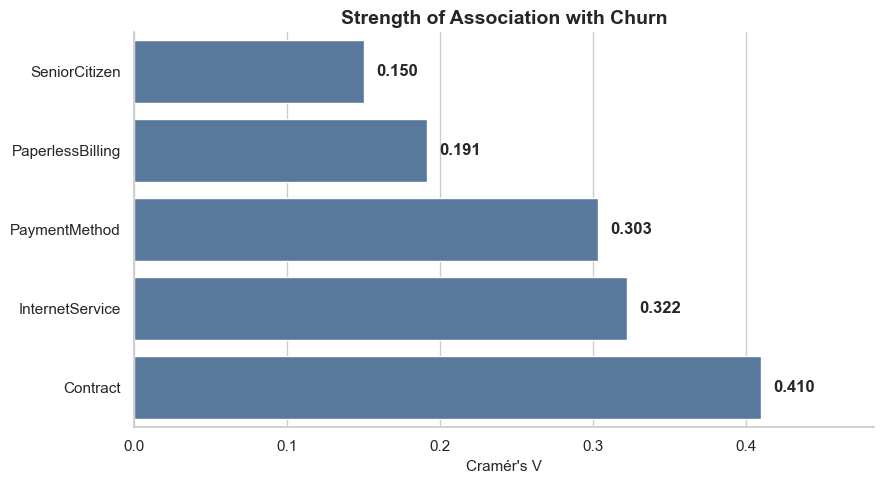

In [94]:
main_effect_plot = (
    main_test_results
    .sort_values("CramersV")
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=main_effect_plot,
    x="CramersV",
    y="Variable",
    color="#4C78A8",
    ax=ax
)

for bar in ax.patches:
    width = bar.get_width()

    ax.text(
        width + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        ha="left",
        va="center",
        fontweight="bold"
    )

ax.set_title("Strength of Association with Churn")
ax.set_xlabel("Cramér's V")
ax.set_ylabel("")
ax.set_xlim(
    0,
    main_test_results["CramersV"].max() * 1.18
)

sns.despine()
plt.tight_layout()

fig.savefig(
    images_path / "categorical_effect_sizes.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

#### 6.2.2 Internet Add-On Tests

In [95]:
addon_test_variables = [
    "OnlineSecurity",
    "TechSupport",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies"
]

In [96]:
addon_test_results = pd.DataFrame(
    [
        run_chi_square_test(
            internet_customers,
            variable
        )
        for variable in addon_test_variables
    ]
)

addon_test_results["Significant"] = (
    addon_test_results["PValue"] < 0.05
)

addon_test_results = (
    addon_test_results
    .sort_values(
        "CramersV",
        ascending=False
    )
    .reset_index(drop=True)
)

addon_test_results.style.format({
    "ChiSquare": "{:,.3f}",
    "PValue": "{:.3e}",
    "CramersV": "{:.3f}",
    "MinimumExpectedFrequency": "{:.2f}"
})

,Variable,ChiSquare,DegreesOfFreedom,PValue,CramersV,MinimumExpectedFrequency,Significant
0,OnlineSecurity,433.808,1,2.410e-96,0.280,642.63,True
1,TechSupport,414.252,1,4.352e-92,0.274,650.58,True
2,OnlineBackup,211.226,1,7.418e-48,0.196,773.12,True
3,DeviceProtection,172.321,1,2.303e-39,0.177,770.90,True
4,StreamingMovies,8.714,1,3.157e-03,0.040,869.57,True
5,StreamingTV,7.418,1,6.458e-03,0.037,861.61,True


**Statistical findings:**

- `Contract` memiliki hubungan terkuat dengan churn di antara faktor kategorikal utama yang diuji, dengan Cramér’s V sebesar 0,410.
- `InternetService` dan `PaymentMethod` juga menunjukkan hubungan yang cukup berarti, masing-masing dengan Cramér’s V sebesar 0,322 dan 0,303.
- `PaperlessBilling` dan `SeniorCitizen` signifikan secara statistik, tetapi kekuatan hubungannya lebih rendah.
- Di antara pelanggan internet, `OnlineSecurity` dan `TechSupport` memiliki hubungan terbesar dengan churn, dengan Cramér’s V sebesar 0,280 dan 0,274.
- `StreamingTV` dan `StreamingMovies` memiliki Cramér’s V mendekati nol. Walaupun p-value berada di bawah 0,05, kekuatan hubungannya sangat kecil secara praktis.

Hasil ini menunjukkan mengapa p-value perlu dibaca bersama effect size. Pada dataset yang cukup besar, perbedaan kecil dapat menghasilkan p-value yang signifikan meskipun hubungan praktisnya sangat lemah.

Uji chi-square menunjukkan hubungan antarvariabel, tetapi tidak membuktikan hubungan sebab-akibat dan tidak memisahkan pengaruh variabel lain.

### 6.3 Numerical Variables and Churn

Welch’s t-test digunakan untuk membandingkan rata-rata `tenure`, `MonthlyCharges`, dan `TotalCharges` antara pelanggan churn dan tidak churn.

Welch’s t-test dipilih karena ukuran dan varians kedua kelompok tidak harus sama. Dengan jumlah observasi yang besar pada kedua kelompok, pengujian rata-rata cukup robust terhadap penyimpangan distribusi normal.

**Hypotheses:**

- **H₀:** Rata-rata variabel pada kelompok churn dan tidak churn sama.
- **H₁:** Rata-rata variabel pada kelompok churn dan tidak churn berbeda.

In [97]:
def calculate_cohens_d(group_a, group_b):
    sample_size_a = len(group_a)
    sample_size_b = len(group_b)

    variance_a = group_a.var(ddof=1)
    variance_b = group_b.var(ddof=1)

    pooled_standard_deviation = np.sqrt(
        (
            (sample_size_a - 1) * variance_a
            + (sample_size_b - 1) * variance_b
        )
        / (
            sample_size_a
            + sample_size_b
            - 2
        )
    )

    cohens_d = (
        group_a.mean() - group_b.mean()
    ) / pooled_standard_deviation

    return cohens_d

In [98]:
# Reusable function to perform Welch's t-test and calculate Cohen's d for any numerical variable
def run_welch_test(data, variable):
    churned_group = data.loc[
        data["Churn"] == "Yes",
        variable
    ].dropna()

    retained_group = data.loc[
        data["Churn"] == "No",
        variable
    ].dropna()

    t_statistic, p_value = ttest_ind(
        churned_group,
        retained_group,
        equal_var=False
    )

    cohens_d = calculate_cohens_d(
        churned_group,
        retained_group
    )

    return {
        "Variable": variable,
        "MeanChurn": churned_group.mean(),
        "MeanNoChurn": retained_group.mean(),
        "MeanDifference": (
            churned_group.mean()
            - retained_group.mean()
        ),
        "TStatistic": t_statistic,
        "PValue": p_value,
        "CohensD": cohens_d
    }

In [99]:
numerical_variables = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

numerical_test_results = pd.DataFrame(
    [
        run_welch_test(
            df_clean,
            variable
        )
        for variable in numerical_variables
    ]
)

numerical_test_results["Significant"] = (
    numerical_test_results["PValue"] < 0.05
)

numerical_test_results

,Variable,MeanChurn,MeanNoChurn,MeanDifference,TStatistic,PValue,CohensD,Significant
0,tenure,17.979133,37.569965,-19.590832,-34.823819,1.195495e-232,-0.852250,True
1,MonthlyCharges,74.441332,61.265124,13.176209,18.407527,8.592449e-73,0.446283,True
2,TotalCharges,1531.796094,2549.911442,-1018.115348,-18.706618,5.902581e-75,-0.458213,True


In [100]:
numerical_test_results.style.format({
    "MeanChurn": "{:,.2f}",
    "MeanNoChurn": "{:,.2f}",
    "MeanDifference": "{:,.2f}",
    "TStatistic": "{:,.3f}",
    "PValue": "{:.3e}",
    "CohensD": "{:.3f}"
})

,Variable,MeanChurn,MeanNoChurn,MeanDifference,TStatistic,PValue,CohensD,Significant
0,tenure,17.98,37.57,-19.59,-34.824,1.195e-232,-0.852,True
1,MonthlyCharges,74.44,61.27,13.18,18.408,8.592e-73,0.446,True
2,TotalCharges,"1,531.80","2,549.91","-1,018.12",-18.707,5.903e-75,-0.458,True


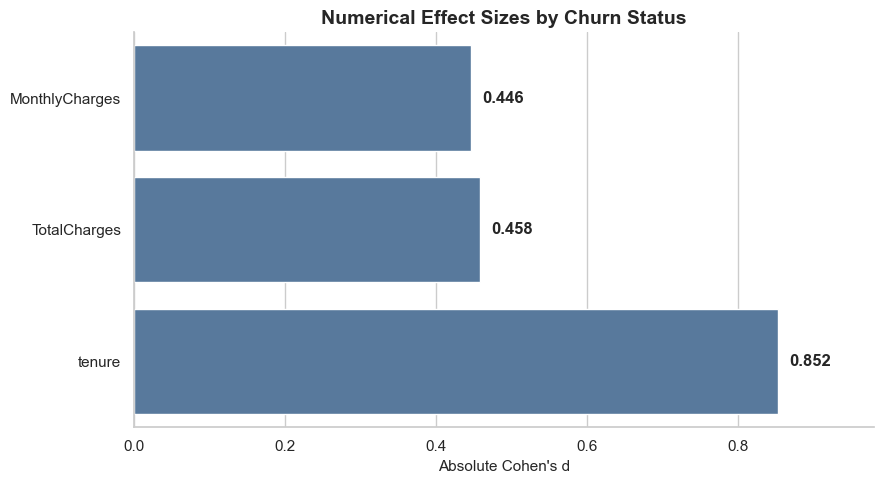

In [101]:
numerical_effect_plot = (
    numerical_test_results
    .assign(
        AbsoluteCohensD=lambda data:
        data["CohensD"].abs()
    )
    .sort_values("AbsoluteCohensD")
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=numerical_effect_plot,
    x="AbsoluteCohensD",
    y="Variable",
    color="#4C78A8",
    ax=ax
)

for bar in ax.patches:
    width = bar.get_width()

    ax.text(
        width + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        ha="left",
        va="center",
        fontweight="bold"
    )

ax.set_title("Numerical Effect Sizes by Churn Status")
ax.set_xlabel("Absolute Cohen's d")
ax.set_ylabel("")
ax.set_xlim(
    0,
    numerical_effect_plot[
        "AbsoluteCohensD"
    ].max() * 1.15
)

sns.despine()
plt.tight_layout()
plt.show()

**Statistical findings:**

- `tenure` memiliki perbedaan yang signifikan antara pelanggan churn dan tidak churn. Rata-rata tenure pelanggan churn lebih rendah sekitar 19,59 bulan. Cohen’s d sebesar -0,852 menunjukkan perbedaan yang besar.
- `MonthlyCharges` pada pelanggan churn rata-rata lebih tinggi sebesar $13,18. Cohen’s d sebesar 0,446 menunjukkan perbedaan kecil hingga menengah.
- `TotalCharges` pada pelanggan churn rata-rata lebih rendah sebesar $1.018,12. Cohen’s d sebesar -0,458 menunjukkan perbedaan kecil hingga menengah.

Ketiga variabel memiliki p-value jauh di bawah 0,05. Namun, tenure menunjukkan perbedaan paling besar antara kelompok churn dan tidak churn.

`TotalCharges` yang lebih rendah pada pelanggan churn tidak berarti kelompok tersebut menerima tarif yang lebih murah. Total biaya merupakan nilai akumulatif dan sangat dipengaruhi oleh tenure yang lebih pendek.

### 6.4 Statistical Analysis Summary

Analisis statistik menghasilkan temuan berikut:

1. `Contract` memiliki hubungan kategorikal terkuat dengan churn, dengan Cramér’s V sebesar 0,410.
2. `InternetService` dan `PaymentMethod` juga menunjukkan hubungan yang cukup berarti dengan churn.
3. Di antara pelanggan internet, `OnlineSecurity` dan `TechSupport` memiliki hubungan terbesar dengan churn dibandingkan layanan tambahan lainnya.
4. `tenure` menunjukkan perbedaan numerik terbesar antara pelanggan churn dan tidak churn, dengan Cohen’s d sebesar -0,852.
5. Pelanggan churn memiliki `MonthlyCharges` yang lebih tinggi dengan effect size kecil hingga menengah.
6. Perbedaan yang signifikan secara statistik tidak membuktikan hubungan sebab-akibat.

Berdasarkan hasil EDA dan analisis statistik, tenure, contract, dan internet service digunakan sebagai dasar segmentasi pelanggan. Payment method dan layanan tambahan akan digunakan untuk memperkaya profil dan menyusun rekomendasi.

## 7. Customer Segmentation

Segmentasi berbasis aturan digunakan untuk membagi pelanggan menjadi kelompok yang mudah dipahami dan dapat digunakan sebagai dasar prioritas retensi.
Aturan segmentasi disusun menggunakan tenure, contract, dan internet service karena ketiganya menunjukkan hubungan yang berarti dengan churn pada analisis sebelumnya.
Setiap pelanggan hanya ditempatkan dalam satu segmen.

### 7.1 Define Customer Segments

Segmen dibentuk berdasarkan kombinasi faktor yang menunjukkan hubungan paling kuat dengan churn:

- `Critical Risk` menangkap pelanggan baru dengan kontrak bulanan dan fiber optic.
- `High Risk` menangkap pelanggan kontrak bulanan pada dua tahun pertama yang tidak termasuk Critical Risk.
- `Elevated Risk` menangkap pelanggan kontrak bulanan dengan tenure lebih panjang.
- `Early Fixed-Term` menangkap pelanggan dengan tenure 0–24 bulan dan kontrak satu atau dua tahun.
- `Established Fixed-Term` menangkap pelanggan dengan tenure lebih dari 24 bulan dan kontrak satu atau dua tahun.

In [102]:
segment_conditions = [
    (
        (df_clean["tenure"] <= 12)
        & (df_clean["Contract"] == "Month-to-month")
        & (df_clean["InternetService"] == "Fiber optic")
    ),
    (
        (df_clean["tenure"] <= 24)
        & (df_clean["Contract"] == "Month-to-month")
    ),
    (
        (df_clean["tenure"] > 24)
        & (df_clean["Contract"] == "Month-to-month")
    ),
    (
        (df_clean["tenure"] <= 24)
        & (df_clean["Contract"] != "Month-to-month")
    ),
    (
        (df_clean["tenure"] > 24)
        & (df_clean["Contract"] != "Month-to-month")
    )
]

segment_labels = [
    "Critical Risk",
    "High Risk",
    "Elevated Risk",
    "Early Fixed-Term",
    "Established Fixed-Term"
]

df_clean["CustomerSegment"] = np.select(
    segment_conditions,
    segment_labels,
    default="Unclassified"
)

In [103]:
df_clean["CustomerSegment"].value_counts()

CustomerSegment
Established Fixed-Term    2689
High Risk                 1815
Elevated Risk             1144
Critical Risk              916
Early Fixed-Term           479
Name: count, dtype: int64

In [104]:
assert (
    df_clean["CustomerSegment"]
    != "Unclassified"
).all()

assert (
    df_clean["CustomerSegment"]
    .value_counts()
    .sum()
    == len(df_clean)
)

print("All customers were assigned to one segment.")

All customers were assigned to one segment.


### 7.2 Segment Performance Summary

In [105]:
segment_order = [
    "Critical Risk",
    "High Risk",
    "Elevated Risk",
    "Early Fixed-Term",
    "Established Fixed-Term"
]

segment_summary = (
    df_clean
    .groupby("CustomerSegment")
    .agg(
        CustomerCount=("customerID", "count"),
        ChurnedCustomers=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean"),
        MeanTenure=("tenure", "mean"),
        MeanMonthlyCharges=("MonthlyCharges", "mean")
    )
    .reindex(segment_order)
    .reset_index()
)

segment_summary["CustomerShare"] = (
    segment_summary["CustomerCount"]
    / len(df_clean)
)

segment_summary["ChurnContribution"] = (
    segment_summary["ChurnedCustomers"]
    / df_clean["ChurnFlag"].sum()
)

In [106]:
segment_summary.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}",
    "MeanTenure": "{:.2f}",
    "MeanMonthlyCharges": "${:,.2f}",
    "CustomerShare": "{:.2%}",
    "ChurnContribution": "{:.2%}"
})

,CustomerSegment,CustomerCount,ChurnedCustomers,ChurnRate,MeanTenure,MeanMonthlyCharges,CustomerShare,ChurnContribution
0,Critical Risk,916,643,70.20%,4.78,$82.08,13.01%,34.40%
1,High Risk,"1,815",659,36.31%,9.85,$50.68,25.77%,35.26%
2,Elevated Risk,"1,144",353,30.86%,41.64,$78.78,16.24%,18.89%
3,Early Fixed-Term,479,29,6.05%,14.36,$38.19,6.80%,1.55%
4,Established Fixed-Term,"2,689",185,6.88%,56.24,$67.14,38.18%,9.90%


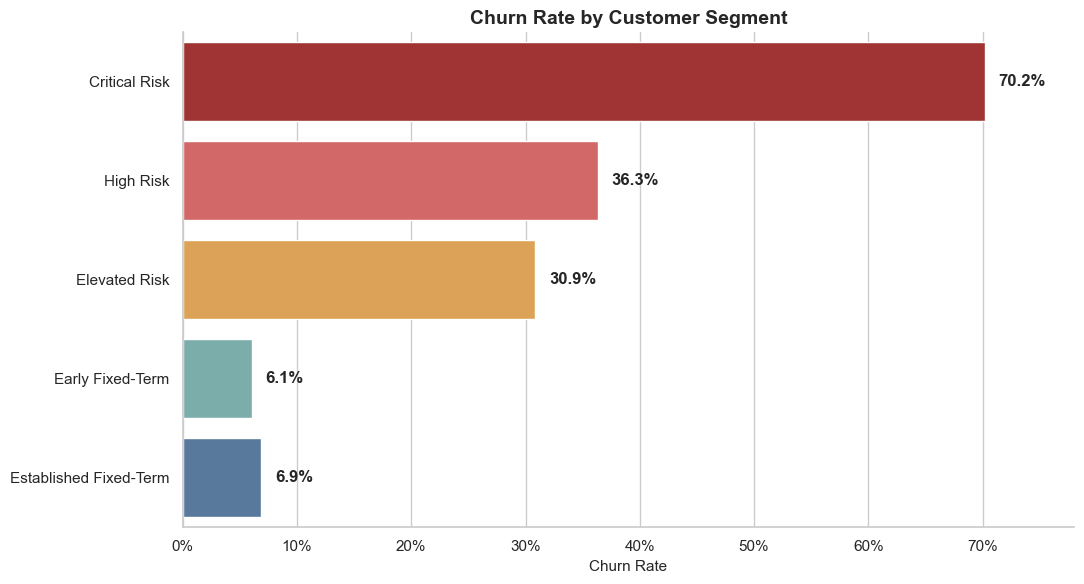

In [107]:
segment_colors = {
    "Critical Risk": "#B22222",
    "High Risk": "#E45756",
    "Elevated Risk": "#F2A541",
    "Early Fixed-Term": "#72B7B2",
    "Established Fixed-Term": "#4C78A8"
}

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=segment_summary,
    x="ChurnRate",
    y="CustomerSegment",
    hue="CustomerSegment",
    palette=segment_colors,
    legend=False,
    ax=ax
)

for bar in ax.patches:
    width = bar.get_width()

    ax.text(
        width + 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1%}",
        ha="left",
        va="center",
        fontweight="bold"
    )

ax.set_title("Churn Rate by Customer Segment")
ax.set_xlabel("Churn Rate")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _: f"{value:.0%}"
    )
)
ax.set_xlim(0, 0.78)

sns.despine()
plt.tight_layout()

fig.savefig(
    images_path / "customer_segment_churn_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

**Segment findings:**

- `Critical Risk` hanya mencakup 13,01% pelanggan, tetapi memiliki churn rate 70,20% dan menyumbang 34,40% dari seluruh pelanggan churn.
- `High Risk` mencakup 25,77% pelanggan dengan churn rate 36,31% dan menyumbang 35,26% dari seluruh churn.
- Jika digabungkan, `Critical Risk` dan `High Risk` mencakup 38,78% pelanggan tetapi menyumbang sekitar 69,66% dari seluruh churn.
- `Elevated Risk` masih memiliki churn rate yang cukup tinggi sebesar 30,86%.
- Kedua segmen fixed-term memiliki churn rate sekitar 6%, jauh lebih rendah dibandingkan segmen kontrak bulanan.

Segmentasi ini merupakan alat prioritas berbasis aturan dan hasil historis dalam dataset. Nama segmen tidak menunjukkan probabilitas prediksi untuk pelanggan individual.

### 7.3 Priority Segment Profiling

Profiling dilakukan untuk memahami karakteristik operasional `Critical Risk` dan `High Risk`. Analisis mencakup tenure, biaya bulanan, metode pembayaran, paperless billing, jenis internet, dan penggunaan layanan dukungan.

In [108]:
priority_segment_order = [
    "Critical Risk",
    "High Risk"
]

priority_customers = df_clean[
    df_clean["CustomerSegment"].isin(
        priority_segment_order
    )
].copy()

In [109]:
priority_profile = (
    priority_customers
    .groupby("CustomerSegment")
    .agg(
        CustomerCount=("customerID", "count"),
        ChurnedCustomers=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean"),
        MeanTenure=("tenure", "mean"),
        MeanMonthlyCharges=("MonthlyCharges", "mean"),
        ElectronicCheckShare=(
            "PaymentMethod",
            lambda values:
            (values == "Electronic check").mean()
        ),
        PaperlessBillingShare=(
            "PaperlessBilling",
            lambda values:
            (values == "Yes").mean()
        )
    )
    .reindex(priority_segment_order)
    .reset_index()
)

priority_profile.style.format({
    "CustomerCount": "{:,.0f}",
    "ChurnedCustomers": "{:,.0f}",
    "ChurnRate": "{:.2%}",
    "MeanTenure": "{:.2f}",
    "MeanMonthlyCharges": "${:,.2f}",
    "ElectronicCheckShare": "{:.2%}",
    "PaperlessBillingShare": "{:.2%}"
})

,CustomerSegment,CustomerCount,ChurnedCustomers,ChurnRate,MeanTenure,MeanMonthlyCharges,ElectronicCheckShare,PaperlessBillingShare
0,Critical Risk,916,643,70.20%,4.78,$82.08,68.89%,78.60%
1,High Risk,"1,815",659,36.31%,9.85,$50.68,37.36%,56.53%


In [110]:
priority_internet_profile = pd.crosstab(
    priority_customers["CustomerSegment"],
    priority_customers["InternetService"],
    normalize="index"
).reindex(priority_segment_order)

priority_internet_profile.style.format(
    "{:.2%}"
)

InternetService,DSL,Fiber optic,No
CustomerSegment,,,
Critical Risk,0.00%,100.00%,0.00%
High Risk,50.80%,23.42%,25.79%


In [111]:
priority_internet_customers = (
    priority_customers[
        priority_customers["InternetService"]
        != "No"
    ]
    .copy()
)

In [112]:
priority_support_profile = (
    priority_internet_customers
    .groupby("CustomerSegment")
    .agg(
        InternetCustomers=(
            "customerID",
            "count"
        ),
        NoOnlineSecurityShare=(
            "OnlineSecurity",
            lambda values:
            (values == "No").mean()
        ),
        NoTechSupportShare=(
            "TechSupport",
            lambda values:
            (values == "No").mean()
        )
    )
    .reindex(priority_segment_order)
    .reset_index()
)

priority_support_profile.style.format({
    "InternetCustomers": "{:,.0f}",
    "NoOnlineSecurityShare": "{:.2%}",
    "NoTechSupportShare": "{:.2%}"
})

,CustomerSegment,InternetCustomers,NoOnlineSecurityShare,NoTechSupportShare
0,Critical Risk,916,90.83%,90.94%
1,High Risk,"1,347",76.54%,77.43%


In [113]:
priority_payment_profile = pd.crosstab(
    priority_customers["CustomerSegment"],
    priority_customers["PaymentMethod"],
    normalize="index"
).reindex(priority_segment_order)

priority_payment_profile.style.format(
    "{:.2%}"
)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
CustomerSegment,,,,
Critical Risk,9.50%,8.19%,68.89%,13.43%
High Risk,13.28%,13.06%,37.36%,36.31%


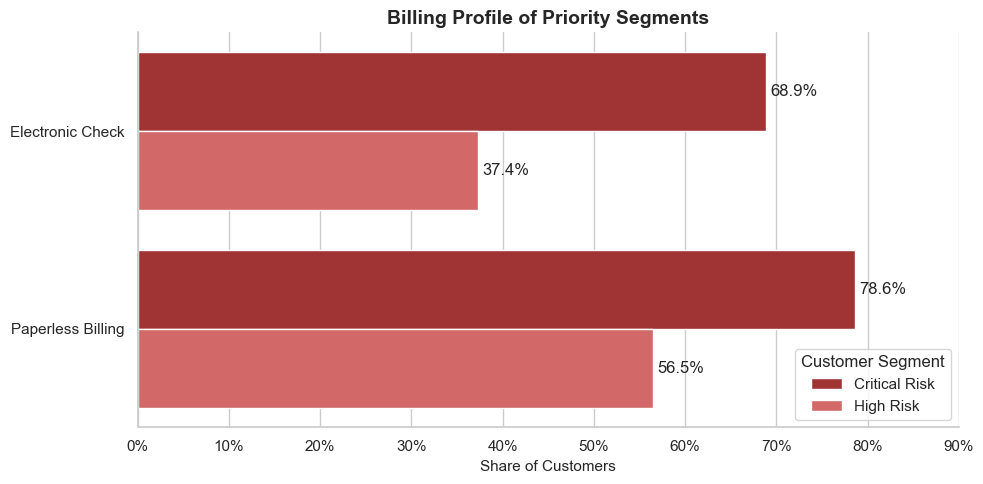

In [114]:
profile_metrics = (
    priority_profile[
        [
            "CustomerSegment",
            "ElectronicCheckShare",
            "PaperlessBillingShare"
        ]
    ]
    .melt(
        id_vars="CustomerSegment",
        var_name="Characteristic",
        value_name="Share"
    )
)

profile_metrics["Characteristic"] = (
    profile_metrics["Characteristic"]
    .replace({
        "ElectronicCheckShare":
            "Electronic Check",
        "PaperlessBillingShare":
            "Paperless Billing"
    })
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=profile_metrics,
    x="Share",
    y="Characteristic",
    hue="CustomerSegment",
    hue_order=priority_segment_order,
    palette={
        "Critical Risk": "#B22222",
        "High Risk": "#E45756"
    },
    ax=ax
)

for container in ax.containers:
    labels = [
        f"{value:.1%}"
        for value in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

ax.set_title("Billing Profile of Priority Segments")
ax.set_xlabel("Share of Customers")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, _: f"{value:.0%}"
    )
)
ax.set_xlim(0, 0.90)
ax.legend(title="Customer Segment")

sns.despine()
plt.tight_layout()
plt.show()

**Priority segment profiles:**

- `Critical Risk` memiliki rata-rata tenure hanya 4,78 bulan, menunjukkan bahwa churn dalam segmen ini terkonsentrasi pada tahap awal hubungan pelanggan.
- Segmen tersebut memiliki rata-rata biaya bulanan $82,08 dan churn rate 70,20%.
- Sebanyak 68,89% pelanggan Critical Risk menggunakan electronic check dan 78,60% menggunakan paperless billing.
- Sekitar 91% pelanggan Critical Risk tidak menggunakan Online Security maupun Tech Support.
- `High Risk` memiliki rata-rata tenure 9,85 bulan dan churn rate 36,31%.
- Di antara pelanggan internet dalam segmen High Risk, sekitar 77% tidak menggunakan Online Security atau Tech Support.

Critical Risk dan High Risk memiliki kombinasi masa berlangganan pendek, kontrak bulanan, rendahnya penggunaan layanan dukungan, dan penggunaan metode pembayaran yang sebelumnya berkaitan dengan churn lebih tinggi.

Karakteristik ini menunjukkan area yang dapat digunakan untuk merancang program retensi. Namun, segmentasi tidak membuktikan bahwa metode pembayaran atau tidak adanya layanan tambahan menyebabkan churn.

### 7.4 Save Final Processed Dataset

Dataset yang telah melalui data cleaning, feature engineering, dan customer segmentation disimpan sebagai processed dataset untuk mendukung reproduksi analisis.

In [115]:
final_processed_path = Path(
    "../data/processed/telco_churn_clean.csv"
)

df_clean.to_csv(
    final_processed_path,
    index=False
)

print(f"Final processed dataset shape: {df_clean.shape}")
print(f"Saved to: {final_processed_path}")

Final processed dataset shape: (7043, 25)
Saved to: ../data/processed/telco_churn_clean.csv


## 8. Key Insights

### 8.1 Churn Affects a Substantial Share of Customers

**Finding:**

Sebanyak 1.869 dari 7.043 pelanggan mengalami churn, menghasilkan churn rate keseluruhan sebesar 26,54%.

**Evidence:**

- Total customers: 7.043
- Churned customers: 1.869
- Overall churn rate: 26,54%

**Business meaning:**

Sekitar satu dari empat pelanggan dalam dataset berhenti berlangganan. Kondisi ini menunjukkan bahwa churn merupakan masalah yang cukup besar untuk dianalisis lebih lanjut, tetapi program retensi perlu diarahkan kepada kelompok tertentu agar lebih terfokus.

---

### 8.2 Churn Is Concentrated Among New Customers

**Finding:**

Kelompok `New Customer` dengan tenure 0–12 bulan memiliki churn rate tertinggi sebesar 47,44%. Tenure digunakan untuk menunjukkan fase customer lifecycle dan tidak dianggap sebagai penyebab churn.

**Evidence:**

- Pelanggan dengan tenure 0–12 bulan memiliki churn rate 47,44%.
- Pelanggan dengan tenure 49–72 bulan memiliki churn rate 9,51%.
- Rata-rata tenure pelanggan churn adalah 17,98 bulan, dibandingkan 37,57 bulan pada pelanggan yang bertahan.
- Perbedaan tenure menghasilkan Cohen’s d sebesar -0,852, yaitu effect size terbesar di antara variabel numerik yang diuji.
- Pelanggan dengan kontrak month-to-month memiliki churn rate 42,71%.
- Sekitar 88,55% dari seluruh pelanggan churn menggunakan kontrak month-to-month.
- `Contract` memiliki hubungan kategorikal terkuat dengan churn, dengan Cramér’s V sebesar 0,410.

**Business meaning:**

Periode awal hubungan pelanggan merupakan tahap yang paling rentan, terutama ketika pelanggan dapat berhenti tanpa komitmen kontrak jangka panjang. Masa awal pelanggan dan jenis kontrak dapat digunakan sebagai dasar utama untuk menentukan prioritas retensi.

---

### 8.3 Churn Is Concentrated in Two Priority Segments

**Finding:**

Segmen `Critical Risk` dan `High Risk` mengonsentrasikan sebagian besar pelanggan churn dalam kelompok yang lebih kecil daripada keseluruhan basis pelanggan.

**Evidence:**

- `Critical Risk` mencakup 916 pelanggan atau 13,01% dari seluruh pelanggan.
- Segmen tersebut memiliki churn rate 70,20% dan menyumbang 34,40% dari seluruh churn.
- `High Risk` mencakup 1.815 pelanggan atau 25,77% dari seluruh pelanggan.
- Segmen tersebut memiliki churn rate 36,31% dan menyumbang 35,26% dari seluruh churn.
- Jika digabungkan, kedua segmen mencakup 38,78% pelanggan tetapi menyumbang sekitar 69,66% dari seluruh churn.

**Business meaning:**

Perusahaan dapat memulai program retensi dari dua segmen tersebut. Pendekatan ini mempersempit populasi prioritas dari seluruh pelanggan menjadi sekitar 39% pelanggan yang mencakup hampir 70% kasus churn dalam dataset.

Segmentasi ini bersifat deskriptif berdasarkan pola historis dan bukan prediksi churn individual.

---

### 8.4 Fiber Optic Customers Without Support Services Require Attention

**Finding:**

Pelanggan fiber optic menunjukkan churn rate tinggi, terutama pada kelompok baru dengan kontrak bulanan. Rendahnya penggunaan Online Security dan Tech Support juga terlihat pada segmen prioritas.

**Evidence:**

- Pelanggan fiber optic memiliki churn rate 41,89%.
- Pelanggan DSL memiliki churn rate 18,96%.
- Di antara pelanggan internet, pelanggan tanpa Online Security memiliki churn rate 41,77%, dibandingkan 14,61% pada pelanggan yang menggunakannya.
- Pelanggan tanpa Tech Support memiliki churn rate 41,64%, dibandingkan 15,17% pada pelanggan yang menggunakannya.
- Online Security dan Tech Support memiliki Cramér’s V sebesar 0,280 dan 0,274 di antara pelanggan internet.
- Sekitar 91% pelanggan `Critical Risk` tidak memiliki Online Security maupun Tech Support.

**Business meaning:**

Pengalaman awal pelanggan fiber optic dan akses terhadap layanan dukungan merupakan area yang perlu ditinjau. Layanan dukungan dapat dipertimbangkan dalam program onboarding atau paket retensi, tetapi efektivitasnya perlu diuji karena data observasional tidak membuktikan bahwa add-on secara langsung mengurangi churn.

---

### 8.5 Monthly Charges and Payment Method Help Identify Retention Priorities

**Finding:**

Pelanggan churn memiliki biaya bulanan yang lebih tinggi, sedangkan electronic check berkaitan dengan churn rate tertinggi di antara metode pembayaran.

**Evidence:**

- Rata-rata Monthly Charges pelanggan churn adalah $74,44.
- Rata-rata Monthly Charges pelanggan yang bertahan adalah $61,27.
- Perbedaannya adalah $13,18 atau sekitar 21,50%.
- Cohen’s d untuk Monthly Charges adalah 0,446.
- Electronic check memiliki churn rate 45,29%.
- Credit card automatic memiliki churn rate 15,24%.
- Bank transfer automatic memiliki churn rate 16,71%.
- `PaymentMethod` memiliki Cramér’s V sebesar 0,303.
- Sebanyak 68,89% pelanggan `Critical Risk` menggunakan electronic check.

**Business meaning:**

Biaya bulanan dan metode pembayaran dapat digunakan sebagai sinyal tambahan untuk memprioritaskan pelanggan dalam segmen berisiko. Perusahaan perlu mengevaluasi apakah pelanggan memahami nilai layanan yang diterima dan apakah pengalaman pembayaran electronic check menimbulkan hambatan.

Hubungan tersebut tidak membuktikan bahwa biaya tinggi atau electronic check secara langsung menyebabkan churn.

## 9. Business Recommendations

Rekomendasi berikut disusun berdasarkan pola churn, hasil pengujian statistik, dan profil segmen pelanggan. Karena data bersifat observasional, setiap tindakan sebaiknya diterapkan melalui program pilot atau eksperimen sebelum diluncurkan kepada seluruh pelanggan.

### 9.1 Strengthen Early Customer Onboarding

**Target segment:**

- `Critical Risk`
- `High Risk`
- Pelanggan dengan tenure 0–12 bulan
- Pelanggan baru dengan kontrak month-to-month

**Supporting evidence:**

- Pelanggan dengan tenure 0–12 bulan memiliki churn rate 47,44%.
- Rata-rata tenure pelanggan churn hanya 17,98 bulan.
- `Critical Risk` memiliki rata-rata tenure 4,78 bulan dan churn rate 70,20%.
- Tenure memiliki effect size terbesar dalam perbandingan kelompok churn dan tidak churn.

**Recommended actions:**

1. Membuat program onboarding selama 30–90 hari pertama.
2. Mengirim panduan penggunaan layanan setelah aktivasi.
3. Melakukan proactive check-in setelah instalasi dan sebelum tagihan pertama.
4. Memberikan jalur bantuan yang jelas bagi pelanggan baru.
5. Menghubungi pelanggan yang mengalami masalah instalasi, aktivasi, atau tagihan awal.

**Evaluation metrics:**

- Churn rate pada 30, 60, dan 90 hari pertama
- Persentase onboarding yang diselesaikan
- Jumlah kontak support pada masa awal
- First-contact resolution rate
- Customer satisfaction setelah onboarding

---

### 9.2 Offer Voluntary Contract Migration

**Target segment:**

- Pelanggan month-to-month dalam `Critical Risk`, `High Risk`, dan `Elevated Risk`
- Pelanggan yang telah menyelesaikan masa onboarding

**Supporting evidence:**

- Kontrak month-to-month memiliki churn rate 42,71%.
- Kontrak satu tahun memiliki churn rate 11,27%.
- Kontrak dua tahun memiliki churn rate 2,83%.
- Sekitar 88,55% pelanggan churn menggunakan kontrak month-to-month.
- `Contract` memiliki Cramér’s V terbesar, yaitu 0,410.

**Recommended actions:**

1. Menawarkan opsi migrasi sukarela ke kontrak satu tahun.
2. Memberikan insentif terbatas, seperti potongan biaya sementara atau tambahan layanan.
3. Menjelaskan manfaat kontrak dengan bahasa yang transparan.
4. Menawarkan migrasi setelah pelanggan melewati pengalaman awal yang positif.
5. Menghindari proses migrasi yang sulit dibatalkan atau tidak dipahami pelanggan.

**Evaluation metrics:**

- Contract conversion rate
- Churn rate setelah migrasi
- Retention rate setelah 3, 6, dan 12 bulan
- Biaya insentif per pelanggan yang berhasil dipertahankan
- Perubahan pendapatan bersih per pelanggan

---

### 9.3 Improve the Fiber Optic Customer Experience

**Target segment:**

- Pelanggan fiber optic
- Pelanggan baru fiber optic dengan kontrak month-to-month
- `Critical Risk`

**Supporting evidence:**

- Fiber optic memiliki churn rate 41,89%.
- `Critical Risk` terdiri dari pelanggan baru dengan kontrak bulanan dan fiber optic.
- Segmen tersebut memiliki churn rate 70,20%.
- Rata-rata Monthly Charges Critical Risk adalah $82,08.

**Recommended actions:**

1. Meninjau pengalaman instalasi dan aktivasi fiber optic.
2. Memonitor gangguan teknis pada masa awal pelanggan.
3. Memberikan pemeriksaan kualitas koneksi setelah instalasi.
4. Menyediakan jalur support khusus untuk masalah awal fiber optic.
5. Menjelaskan komponen biaya dan manfaat paket kepada pelanggan.

**Evaluation metrics:**

- Churn rate pelanggan fiber optic baru
- Jumlah keluhan setelah instalasi
- Waktu penyelesaian gangguan
- Repeat contact rate
- Customer satisfaction setelah instalasi

---

### 9.4 Test Support-Service Bundles

**Target segment:**

- Pelanggan internet dalam `Critical Risk` dan `High Risk`
- Pelanggan tanpa Online Security
- Pelanggan tanpa Tech Support

**Supporting evidence:**

- Sekitar 91% pelanggan Critical Risk tidak memiliki Online Security maupun Tech Support.
- Pelanggan tanpa Online Security memiliki churn rate 41,77%.
- Pelanggan tanpa Tech Support memiliki churn rate 41,64%.
- Online Security dan Tech Support memiliki hubungan yang lebih berarti dengan churn dibandingkan layanan streaming.

**Recommended actions:**

1. Menawarkan uji coba Online Security atau Tech Support.
2. Memasukkan layanan dukungan dalam paket onboarding.
3. Menguji bundling layanan dengan harga sederhana dan transparan.
4. Menjelaskan manfaat layanan menggunakan contoh yang mudah dipahami.
5. Membandingkan hasil pelanggan yang menerima penawaran dengan kelompok kontrol.

**Evaluation metrics:**

- Add-on adoption rate
- Churn rate setelah penawaran
- Support utilization rate
- Conversion setelah masa uji coba
- Incremental retention dibandingkan kelompok kontrol
- Pendapatan bersih setelah memperhitungkan biaya layanan

---

### 9.5 Encourage Migration to Automatic Payment

**Target segment:**

- Pelanggan electronic check
- Pelanggan electronic check dalam `Critical Risk` dan `High Risk`

**Supporting evidence:**

- Electronic check memiliki churn rate 45,29%.
- Credit card automatic memiliki churn rate 15,24%.
- Bank transfer automatic memiliki churn rate 16,71%.
- Sebanyak 68,89% pelanggan Critical Risk menggunakan electronic check.
- `PaymentMethod` memiliki Cramér’s V sebesar 0,303.

**Recommended actions:**

1. Menyederhanakan proses pendaftaran pembayaran otomatis.
2. Menjelaskan jadwal dan keamanan pembayaran secara transparan.
3. Memberikan pengingat sebelum pembayaran pertama.
4. Menguji insentif kecil untuk migrasi ke automatic payment.
5. Meneliti apakah electronic check berkaitan dengan kegagalan pembayaran atau hambatan proses pembayaran.

**Evaluation metrics:**

- Automatic payment conversion rate
- Payment failure rate
- Late-payment rate
- Churn rate setelah perubahan metode pembayaran
- Jumlah pertanyaan atau keluhan pembayaran

---

### 9.6 Review Price and Service Value

**Target segment:**

- Pelanggan dengan Monthly Charges tinggi
- Pelanggan fiber optic dalam segmen prioritas
- Pelanggan yang membayar layanan tetapi jarang menggunakannya

**Supporting evidence:**

- Rata-rata Monthly Charges pelanggan churn adalah $74,44.
- Rata-rata Monthly Charges pelanggan yang bertahan adalah $61,27.
- Perbedaan rata-ratanya sebesar $13,18 atau sekitar 21,50%.
- Monthly Charges memiliki Cohen’s d sebesar 0,446.

**Recommended actions:**

1. Memberikan penjelasan tagihan yang lebih mudah dipahami.
2. Menawarkan pemeriksaan paket kepada pelanggan berbiaya tinggi.
3. Mengidentifikasi layanan yang tidak lagi relevan bagi pelanggan.
4. Menawarkan paket yang lebih sesuai dengan kebutuhan penggunaan.
5. Mengumpulkan data penggunaan layanan untuk mengevaluasi kesesuaian harga dan manfaat.

**Evaluation metrics:**

- Churn rate pelanggan berbiaya tinggi
- Plan adjustment rate
- Perubahan Monthly Charges setelah penyesuaian
- Retention rate setelah review paket
- Average revenue per customer
- Jumlah keluhan mengenai tagihan

---

### 9.7 Prioritize Recommendations

Rekomendasi dapat diterapkan secara bertahap berdasarkan tingkat urgensi dan kebutuhan pengujian.

| Priority | Initiative | Primary Target |
|---|---|---|
| 1 | Early customer onboarding | Critical Risk dan High Risk |
| 2 | Fiber optic experience review | Critical Risk |
| 3 | Voluntary contract migration | Month-to-month customers |
| 4 | Automatic payment migration | Electronic check customers |
| 5 | Support-service bundle pilot | Internet customers without support |
| 6 | Price and service value review | High-charge customers |

Prioritas pertama ditempatkan pada onboarding karena kelompok New Customer mencakup 31,04% pelanggan dan memiliki churn rate 47,44%. Analisis lanjutan juga menunjukkan bahwa churn pada kelompok ini terkonsentrasi pada pelanggan fiber optic, electronic check, month-to-month, serta pelanggan tanpa layanan dukungan. Tenure digunakan untuk menentukan waktu intervensi, sedangkan efektivitas onboarding perlu diuji melalui program pilot.

---

### 9.8 Measurement and Experimentation Plan

Setiap rekomendasi sebaiknya dimulai melalui program pilot dengan kelompok perlakuan dan kelompok kontrol.

Contoh evaluasi:

1. Pilih pelanggan yang memenuhi kriteria segmen.
2. Bagi pelanggan secara acak menjadi treatment dan control group.
3. Terapkan tindakan hanya pada treatment group.
4. Ukur churn rate dan retention rate pada periode yang sama.
5. Hitung perbedaan hasil antara kedua kelompok.
6. Evaluasi biaya program dan nilai pelanggan yang berhasil dipertahankan.
7. Perluas program hanya jika menunjukkan dampak positif yang cukup besar.

Metrik utama yang perlu dipantau:

- Churn rate
- Retention rate
- Incremental retention
- Contract conversion rate
- Automatic payment adoption
- Add-on adoption
- Customer satisfaction
- Cost per retained customer
- Revenue retained
- Complaint rate

Pendekatan eksperimen diperlukan karena pola historis dalam dataset menunjukkan hubungan, tetapi belum membuktikan bahwa rekomendasi tersebut akan menyebabkan penurunan churn.

## 10. Limitations

Analisis ini memiliki beberapa keterbatasan yang perlu dipertimbangkan ketika menafsirkan hasil.

### 10.1 Fictional Dataset

Dataset menggambarkan perusahaan telekomunikasi fiktif. Hasil analisis digunakan untuk menunjukkan proses analisis data dan tidak dapat langsung digeneralisasi ke perusahaan telekomunikasi tertentu.

### 10.2 Observational Data

Dataset bersifat observasional. Hubungan antara tenure, contract, payment method, services, charges, dan churn tidak membuktikan hubungan sebab-akibat.

Sebagai contoh, pelanggan yang menggunakan Tech Support memiliki churn rate lebih rendah. Namun, data ini belum membuktikan bahwa menambahkan Tech Support akan menyebabkan pelanggan bertahan lebih lama.

### 10.3 Limited Time Information

Dataset tidak memiliki tanggal aktivasi, tanggal churn, atau riwayat pelanggan dari beberapa periode. Variabel `tenure` hanya menunjukkan lama berlangganan dalam bulan.

Akibatnya, analisis tidak dapat:

- Mengukur perubahan churn dari waktu ke waktu.
- Mengidentifikasi tren musiman.
- Menentukan waktu churn secara tepat.
- Menghitung retention cohort berdasarkan tanggal bergabung.
- Melakukan survival analysis secara lengkap.

### 10.4 No Direct Churn Reasons

Dataset tidak menyediakan alasan pelanggan berhenti berlangganan. Pola seperti biaya tinggi, electronic check, atau tidak adanya layanan dukungan hanya menunjukkan hubungan dengan churn.

Diperlukan data survei, alasan pembatalan, keluhan, atau catatan interaksi pelanggan untuk memahami penyebab churn secara lebih langsung.

### 10.5 No Service Usage and Quality Data

Dataset menunjukkan layanan yang dimiliki pelanggan, tetapi tidak menunjukkan:

- Frekuensi penggunaan layanan.
- Kecepatan atau kualitas koneksi.
- Jumlah gangguan teknis.
- Durasi gangguan.
- Jumlah tiket customer support.
- Waktu penyelesaian masalah.
- Kepuasan pelanggan.

Ketiadaan data tersebut membatasi analisis pengalaman pelanggan, terutama untuk pelanggan fiber optic.

### 10.6 No Financial Impact Data

Dataset tidak menyediakan informasi mengenai:

- Margin pelanggan.
- Customer acquisition cost.
- Biaya layanan.
- Biaya program retensi.
- Customer lifetime value.
- Nilai diskon atau insentif.
- Pendapatan setelah pelanggan bertahan.

Oleh karena itu, analisis belum dapat menghitung potensi keuntungan finansial dari setiap rekomendasi retensi.

### 10.7 Total Charges Depend on Tenure

`TotalCharges` merupakan nilai akumulatif yang sangat dipengaruhi oleh lama berlangganan. Pelanggan churn memiliki Total Charges lebih rendah karena mereka cenderung memiliki tenure yang lebih pendek.

Variabel ini tidak dapat ditafsirkan sebagai indikator harga tanpa mempertimbangkan tenure.

### 10.8 Rule-Based Segmentation

Customer segmentation dibuat menggunakan aturan berdasarkan tenure, contract, dan internet service. Segmentasi ini mudah dijelaskan kepada bisnis, tetapi tidak menghasilkan probabilitas churn untuk setiap pelanggan.

Batas tenure yang digunakan juga merupakan pembagian analitis yang perlu divalidasi jika diterapkan pada data perusahaan nyata.

### 10.9 Statistical Significance and Business Impact

Ukuran dataset yang cukup besar dapat menghasilkan p-value yang kecil meskipun perbedaannya tidak besar secara praktis. Oleh karena itu, hasil pengujian dibaca bersama Cramér’s V, Cohen’s d, ukuran segmen, dan konteks bisnis.

### 10.10 Recommendations Require Validation

Rekomendasi dalam proyek ini merupakan hipotesis tindakan berdasarkan pola historis. Efektivitas onboarding, contract migration, support bundle, atau automatic payment perlu diuji melalui program pilot atau eksperimen terkontrol sebelum diterapkan secara luas.

## 11. Conclusion

Analisis terhadap 7.043 pelanggan menunjukkan bahwa 1.869 pelanggan mengalami churn, menghasilkan churn rate sebesar 26,54%.

Secara deskriptif, churn terkonsentrasi pada kelompok `New Customer` dengan tenure 0–12 bulan, yang memiliki churn rate 47,44%, dibandingkan 9,51% pada pelanggan dengan tenure 49–72 bulan. Tenure digunakan sebagai penanda fase customer lifecycle dan tidak dianggap sebagai penyebab langsung churn.

Sementara itu, `Contract` merupakan variabel kategorikal dengan hubungan terkuat terhadap churn. Pelanggan dengan kontrak month-to-month memiliki churn rate 42,71% dan menyumbang sekitar 88,55% dari seluruh pelanggan churn.

Jenis layanan internet, metode pembayaran, dan penggunaan layanan dukungan juga menunjukkan hubungan dengan churn. Pelanggan fiber optic, pengguna electronic check, serta pelanggan internet tanpa Online Security atau Tech Support memiliki churn rate yang lebih tinggi.

Segmentasi berbasis tenure, contract, dan internet service mengidentifikasi dua kelompok prioritas:

- `Critical Risk` mencakup 13,01% pelanggan dan menyumbang 34,40% dari seluruh churn.
- `High Risk` mencakup 25,77% pelanggan dan menyumbang 35,26% dari seluruh churn.

Jika digabungkan, kedua segmen mencakup sekitar 38,78% pelanggan tetapi menyumbang sekitar 69,66% dari seluruh churn. Hasil ini memberikan dasar yang lebih terfokus untuk menentukan pelanggan yang dapat diprioritaskan dalam program retensi.

Tindakan yang dapat diuji meliputi:

1. Memperkuat onboarding selama masa awal pelanggan.
2. Meninjau pengalaman pelanggan fiber optic.
3. Menawarkan migrasi sukarela dari kontrak bulanan.
4. Menguji bundling Online Security atau Tech Support.
5. Mendorong migrasi dari electronic check ke automatic payment.
6. Mengevaluasi kesesuaian harga dan manfaat layanan.

Karena dataset bersifat observasional dan menggambarkan perusahaan fiktif, rekomendasi tersebut perlu divalidasi melalui eksperimen, data operasional tambahan, dan evaluasi finansial sebelum digunakan untuk pengambilan keputusan nyata.

Secara keseluruhan, analisis menunjukkan bahwa churn tidak tersebar secara merata. Churn terkonsentrasi pada pelanggan baru dengan kontrak fleksibel dan karakteristik layanan tertentu, sehingga pendekatan retensi berbasis segmen lebih relevan daripada menerapkan perlakuan yang sama kepada seluruh pelanggan.